In [1]:
from pathlib import Path
import os, sys, json, math, random, re, shutil, time
from collections import Counter, defaultdict
from tqdm import tqdm
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

SEED = 1337
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)




LANG = "ne"


DATASET_ROOT = Path(
    "/kaggle/input/datasets/gulgulasaur/reasoning-data-generation-summary"
)
MODEL_ROOT = Path(
    f"/kaggle/input/notebooks/gulgulasaur/lma-{'hindi' if LANG == 'hi' else 'nepali'}"
)

OUT = Path("/kaggle/working") / f"phase3_{LANG}"
SRC_OUT = OUT / "src"
CKPT_OUT = OUT / "checkpoints"
PLOT_OUT = OUT / "plots"
METRIC_OUT = OUT / "metrics"
LOG_OUT = OUT / "logs"

for d in (OUT, SRC_OUT, CKPT_OUT, PLOT_OUT, METRIC_OUT, LOG_OUT):
    d.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

LANG_INFO = {
    "hi": {
        "name": "Hindi",
        "dataset_dir": DATASET_ROOT / "hindi" / "reasoning" / "data",
        "tokenizer_name": "hindi_bpe16k",
    },
    "ne": {
        "name": "Nepali",
        "dataset_dir": DATASET_ROOT / "nepali" / "reasoning" / "data",
        "tokenizer_name": "nepali_bpe16k",
    },
}
if LANG not in LANG_INFO:
    raise ValueError("LANG must be 'hi' or 'ne'.")

INFO = LANG_INFO[LANG]
DATASET_DIR = INFO["dataset_dir"]


required_inputs = {
    "dataset_dir": DATASET_DIR,
    "dataset_summary": DATASET_ROOT / "reasoning_data_generation_summary.json",
    "model.py": MODEL_ROOT / "model.py",
    "tokenizers.py": MODEL_ROOT / "tokenizers.py",
    "checkpoint": MODEL_ROOT / "ckpt" / "last.pt",
    "tokenizer": MODEL_ROOT / "tokenizer" / f"{INFO['tokenizer_name']}.pkl",
    "train": DATASET_DIR / "train.jsonl",
    "val": DATASET_DIR / "val.jsonl",
    "test": DATASET_DIR / "test.jsonl",
}
missing = [f"{name}: {path}" for name, path in required_inputs.items() if not path.exists()]
if missing:
    raise FileNotFoundError(
        "Required Kaggle input paths were not found:\n" + "\n".join(missing)
    )

MODEL_PY = required_inputs["model.py"]
TOKENIZERS_PY = required_inputs["tokenizers.py"]
CKPT_PATH = required_inputs["checkpoint"]
TOKENIZER_PKL = required_inputs["tokenizer"]
TRAIN_JSONL = required_inputs["train"]
VAL_JSONL = required_inputs["val"]
TEST_JSONL = required_inputs["test"]

print("Language:", INFO["name"])
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

print("\nInputs:")
for name, path in required_inputs.items():
    print(f"{name:12s}: {path}")

print("\nOutputs:")
print(OUT)

Language: Nepali
Device: cuda
GPU: Tesla T4

Inputs:
model.py    : /kaggle/input/notebooks/gulgulasaur/lma-nepali/model.py
tokenizers.py: /kaggle/input/notebooks/gulgulasaur/lma-nepali/tokenizers.py
checkpoint  : /kaggle/input/notebooks/gulgulasaur/lma-nepali/ckpt/last.pt
tokenizer   : /kaggle/input/notebooks/gulgulasaur/lma-nepali/tokenizer/nepali_bpe16k.pkl
train       : /kaggle/input/datasets/gulgulasaur/hindi-nepali-sft/hindi/reasoning/data/train.jsonl
val         : /kaggle/input/datasets/gulgulasaur/hindi-nepali-sft/hindi/reasoning/data/val.jsonl
test        : /kaggle/input/datasets/gulgulasaur/hindi-nepali-sft/hindi/reasoning/data/test.jsonl

Outputs:
/kaggle/working/phase3_ne


In [2]:


shutil.copy2(MODEL_PY, SRC_OUT / "model.py")
shutil.copy2(TOKENIZERS_PY, SRC_OUT / "tokenizers.py")

sys.path.insert(0, str(SRC_OUT))

from model import GPTLanguageModel
from tokenizers import customBPE

print("Loaded GPTLanguageModel and customBPE from the supplied Phase 2 files.")

Loaded GPTLanguageModel and customBPE from the supplied Phase 2 files.


## 1. Load the fixed tokenizer

The Phase 3 protocol requires the language's existing tokenizer/vocabulary to remain fixed. We only load it here. No tokenizer training occurs.

In [3]:
tokenizer = customBPE()
tokenizer.load(str(TOKENIZER_PKL))

VOCAB = tokenizer.vocab
ID_TO_TOKEN = {int(i): t for t, i in VOCAB.items()}

PAD_ID = VOCAB.get("<pad>")
BOS_ID = VOCAB.get("<bos>")
EOS_ID = VOCAB.get("<eos>")
BOW_ID = VOCAB.get("▁")
UNK_ID = VOCAB.get("UNK", 0)

if PAD_ID is None:
    raise ValueError("Tokenizer does not contain <pad>.")
if BOW_ID is None:
    raise ValueError("Tokenizer does not contain the ▁ boundary token.")

VOCAB_SIZE = max(ID_TO_TOKEN) + 1

print("Tokenizer:", TOKENIZER_PKL)
print("Vocabulary size:", VOCAB_SIZE)
print("Special IDs:", {
    "PAD": PAD_ID,
    "BOS": BOS_ID,
    "EOS": EOS_ID,
    "BOW": BOW_ID,
    "UNK": UNK_ID,
})

Tokenizer: /kaggle/input/notebooks/gulgulasaur/lma-nepali/tokenizer/nepali_bpe16k.pkl
Vocabulary size: 14223
Special IDs: {'PAD': 14219, 'BOS': 14220, 'EOS': 14221, 'BOW': 14222, 'UNK': 0}


## 2. Tokenization glue used by Phase 2

`customBPE.tokenize()` returns subword pieces but does not preserve whitespace. Phase 2 therefore used the `▁` boundary token around each pre-tokenized word. The same encoding/decoding convention is reused here.

In [4]:
def encode_text(text, add_bos=False, add_eos=False):
    ids = []
    if add_bos and BOS_ID is not None:
        ids.append(BOS_ID)

    words = tokenizer.pre_tokenizer.tokenize(text)
    for word in words:
        ids.append(BOW_ID)

        pieces = tokenizer._token_cache.get(word)
        if pieces is None:
            pieces = tokenizer.tokenize(word)

        for piece in pieces:
            ids.append(VOCAB.get(piece, UNK_ID))

    if add_eos and EOS_ID is not None:
        ids.append(EOS_ID)

    return ids

def decode_ids(ids):
    words = []
    current = ""

    for raw_id in ids:
        token = ID_TO_TOKEN.get(int(raw_id), "")

        if token == "▁":
            if current:
                words.append(current)
            current = ""
        elif token in {"<pad>", "<bos>", "<eos>"}:
            continue
        else:
            current += token

    if current:
        words.append(current)

    return " ".join(words)

sample = "भारत एक महान देश है।"
encoded = encode_text(sample)
print("Sample:", sample)
print("Encoded:", encoded[:30])
print("Decoded:", decode_ids(encoded))

Sample: भारत एक महान देश है।
Encoded: [14222, 161, 14222, 25, 14222, 10091, 14222, 2689, 14222, 7938, 11]
Decoded: भारत एक महान देश है।


## 3. Load the Phase 2 checkpoint

The checkpoint created by the Phase 2 notebook contains the architecture fields:

- `vocab_size`
- `d_model`
- `n_heads`
- `n_layers`
- `d_ff`
- `step`
- `model`

We reconstruct the exact architecture from the checkpoint instead of manually guessing it.

In [5]:
raw_ckpt = torch.load(CKPT_PATH, map_location="cpu")

if "model" not in raw_ckpt:
    raise KeyError(f"Expected checkpoint key 'model'. Found: {list(raw_ckpt.keys())}")

def ckpt_value(name, fallback=None):
    if name in raw_ckpt:
        return raw_ckpt[name]
    if "config" in raw_ckpt and isinstance(raw_ckpt["config"], dict):
        return raw_ckpt["config"].get(name, fallback)
    return fallback

CKPT_VOCAB_SIZE = int(ckpt_value("vocab_size", 0))
D_MODEL = int(ckpt_value("d_model", 0))
N_HEADS = int(ckpt_value("n_heads", 0))
N_LAYERS = int(ckpt_value("n_layers", 0))
D_FF = int(ckpt_value("d_ff", 0))

state = raw_ckpt["model"]


if not CKPT_VOCAB_SIZE:
    CKPT_VOCAB_SIZE = state["token_emb.weight"].shape[0]
if not D_MODEL:
    D_MODEL = state["token_emb.weight"].shape[1]
if not N_LAYERS:
    N_LAYERS = max(
        int(k.split(".")[1]) for k in state if k.startswith("blocks.") and k.endswith(".ln1.weight")
    ) + 1
if not D_FF:
    D_FF = state["blocks.0.ffn.linear1.weight"].shape[0]

CONTEXT_LEN = int(state["pos_emb.weight"].shape[0])

print("Checkpoint:", CKPT_PATH)
print("Pretraining step:", raw_ckpt.get("step", "unknown"))
print("Architecture:")
print(f"  vocab_size = {CKPT_VOCAB_SIZE:,}")
print(f"  d_model    = {D_MODEL}")
print(f"  n_heads    = {N_HEADS}")
print(f"  n_layers   = {N_LAYERS}")
print(f"  d_ff       = {D_FF}")
print(f"  context    = {CONTEXT_LEN}")
print(f"  parameters = {sum(v.numel() for v in state.values()):,}")

if CKPT_VOCAB_SIZE != VOCAB_SIZE:
    raise ValueError(
        f"Tokenizer/checkpoint vocabulary mismatch: tokenizer={VOCAB_SIZE}, checkpoint={CKPT_VOCAB_SIZE}"
    )

Checkpoint: /kaggle/input/notebooks/gulgulasaur/lma-nepali/ckpt/last.pt
Pretraining step: 6770
Architecture:
  vocab_size = 14,223
  d_model    = 576
  n_heads    = 4
  n_layers   = 4
  d_ff       = 2304
  context    = 256
  parameters = 32,750,848


In [6]:
model = GPTLanguageModel(
    vocab_size=CKPT_VOCAB_SIZE,
    d_model=D_MODEL,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    d_ff=D_FF,
    context_len=CONTEXT_LEN,
    dropout=0.1,
    pad_token_id=PAD_ID,
)

missing, unexpected = model.load_state_dict(state, strict=True)
model.to(DEVICE)

print("Checkpoint loaded successfully.")
print("Missing keys:", missing)
print("Unexpected keys:", unexpected)
print("Trainable parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

Checkpoint loaded successfully.
Missing keys: []
Unexpected keys: []
Trainable parameters: 24,296,256


## 4. Load the synthetic reasoning dataset

The current generator produces 15 task families (comparison, transitive,
arithmetic, percentage, ratio, algebra, unit_conversion, speed_distance,
physics_fma, physics_density, physics_work, multi_hop, logic, common_sense,
counting) with exact train/validation/test sizes. Answers are no longer
uniformly short numbers: comparison/transitive tasks answer with a name,
logic tasks answer "yes"/"no", direction tasks answer "increase"/"decrease",
and common_sense tasks answer with a short natural-language phrase. Each
example also carries a `difficulty` tier (easy/medium/hard).

We retain the metadata for per-task and per-difficulty evaluation and
leakage/error analysis.


In [7]:
def read_jsonl(path):
    rows = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                rows.append(json.loads(line))
    return rows

train_rows = read_jsonl(TRAIN_JSONL)
val_rows = read_jsonl(VAL_JSONL)
test_rows = read_jsonl(TEST_JSONL)

print("Dataset sizes:")
print("  train:", len(train_rows))
print("  val:  ", len(val_rows))
print("  test: ", len(test_rows))

for split_name, rows in [("train", train_rows), ("val", val_rows), ("test", test_rows)]:
    counts = Counter(r["task_type"] for r in rows)
    print(f"\n{split_name} task distribution:")
    for k, v in sorted(counts.items()):
        print(f"  {k:15s}: {v:,}")

print("\nExample:")
print(json.dumps(train_rows[0], ensure_ascii=False, indent=2))

Dataset sizes:
  train: 15000
  val:   2000
  test:  1000

train task distribution:
  algebra        : 1,200
  arithmetic     : 1,050
  common_sense   : 1,050
  comparison     : 1,050
  counting       : 600
  logic          : 1,050
  multi_hop      : 1,350
  percentage     : 1,050
  physics_density: 750
  physics_fma    : 900
  physics_work   : 750
  ratio          : 1,050
  speed_distance : 1,050
  transitive     : 1,050
  unit_conversion: 1,050

val task distribution:
  algebra        : 160
  arithmetic     : 140
  common_sense   : 140
  comparison     : 140
  counting       : 80
  logic          : 140
  multi_hop      : 180
  percentage     : 140
  physics_density: 100
  physics_fma    : 120
  physics_work   : 100
  ratio          : 140
  speed_distance : 140
  transitive     : 140
  unit_conversion: 140

test task distribution:
  algebra        : 80
  arithmetic     : 70
  common_sense   : 70
  comparison     : 70
  counting       : 40
  logic          : 70
  multi_hop      : 90
  

In [8]:

assert len(train_rows) == 15000, f"Expected 15000 train examples, got {len(train_rows)}"
assert len(val_rows) == 2000, f"Expected 2000 val examples, got {len(val_rows)}"
assert len(test_rows) == 1000, f"Expected 1000 test examples, got {len(test_rows)}"

all_ids = [r["id"] for r in train_rows + val_rows + test_rows]
assert len(all_ids) == len(set(all_ids)), "Duplicate IDs detected."

for row in train_rows + val_rows + test_rows:
    assert isinstance(row["question"], str) and row["question"].strip()
    assert isinstance(row["answer"], str) and row["answer"].strip()


SUMMARY_PATH = required_inputs["dataset_summary"]
with open(SUMMARY_PATH, "r", encoding="utf-8") as f:
    generation_summary = json.load(f)

summary_lang = generation_summary["languages"][LANG]["counts"]
assert summary_lang["train"] == len(train_rows) == 50000
assert summary_lang["val"] == len(val_rows) == 5000
assert summary_lang["test"] == len(test_rows) == 5000

print("Dataset validation passed.")
print("Generator summary matches: 50,000 train / 5,000 val / 5,000 test.")

Dataset validation passed.


## 5. SFT formatting and loss masking

Each example becomes:

```text
<question>
उत्तर: <answer>
```

The model is trained only on the answer portion.

Because `GPTLanguageModel.forward()` computes cross-entropy at the **same position** rather than shifting the targets internally, the first answer token is placed at the final prompt position:

```text
input:  prompt[0] ... prompt[p-1] answer[0] answer[1] ...
label:  PAD       ... PAD       answer[0] answer[1] ...
```

This is the correct causal-LM alignment for the supplied `model.py`.

In [9]:
ANSWER_PREFIX = "उत्तर:"

def format_example(row):
    prompt = row["question"].strip() + "\n" + ANSWER_PREFIX
    answer = row["answer"].strip()
    return prompt, answer

def make_sft_sequence(row):
    prompt, answer = format_example(row)

    prompt_ids = encode_text(prompt)
    answer_ids = encode_text(answer)


    if not answer_ids:
        raise ValueError(f"Empty tokenized answer for {row['id']}")

    full_ids = prompt_ids + answer_ids



    labels = [PAD_ID] * max(0, len(prompt_ids) - 1) + answer_ids


    labels = labels[:len(full_ids)]
    full_ids = full_ids[:len(labels)]

    return full_ids, labels

for row in train_rows[:3]:
    ids, labels = make_sft_sequence(row)
    print("\nQUESTION:", row["question"])
    print("ANSWER:  ", row["answer"])
    print("tokens:", len(ids))
    print("supervised positions:", sum(x != PAD_ID for x in labels))


QUESTION: अमित और निखिल के पास वस्तुओं की संख्या का अनुपात 4:5 है। यदि अमित के पास 36 वस्तुएँ हैं, तो निखिल के पास कितनी हैं?
ANSWER:   45
tokens: 76
supervised positions: 3

QUESTION: कंप्यूटर की ऊँचाई 72 सेंटीमीटर है, जबकि कैलकुलेटर की ऊँचाई 77 सेंटीमीटर है। कौन लंबा है?
ANSWER:   कैलकुलेटर
tokens: 66
supervised positions: 6

QUESTION: गेंद का वजन 80 किलोग्राम है और लैंप का वजन 68 किलोग्राम है। किसका वजन अधिक है?
ANSWER:   गेंद
tokens: 53
supervised positions: 4


In [10]:
MAX_SEQ_LEN = CONTEXT_LEN
BATCH_SIZE = 32
GRAD_ACCUM_STEPS = 1

def build_tensor_pair(row):
    ids, labels = make_sft_sequence(row)


    if len(ids) > MAX_SEQ_LEN:
        ids = ids[-MAX_SEQ_LEN:]
        labels = labels[-MAX_SEQ_LEN:]

    x = torch.full((MAX_SEQ_LEN,), PAD_ID, dtype=torch.long)
    y = torch.full((MAX_SEQ_LEN,), PAD_ID, dtype=torch.long)

    x[:len(ids)] = torch.tensor(ids, dtype=torch.long)
    y[:len(labels)] = torch.tensor(labels, dtype=torch.long)
    return x, y

class ReasoningDataset(Dataset):
    def __init__(self, rows):
        self.rows = rows

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        return build_tensor_pair(self.rows[idx])

train_ds = ReasoningDataset(train_rows)
val_ds = ReasoningDataset(val_rows)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)
val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))

Train batches: 469
Val batches: 63


## 6. Pretrained baseline reasoning accuracy

Before updating any weights, measure exact-match reasoning accuracy on the held-out test set.

This is the key baseline for the required **pretrained vs. fine-tuned** comparison.

In [11]:
def normalize_answer(text):
    text = text.strip().lower()
    text = re.sub(r"[\s\u200b]+", " ", text)
    text = re.sub(r"[।,.!?;:]+$", "", text)
    return text.strip()










def answer_token_length(answer):
    return len(encode_text(answer.strip()))

MAX_ANSWER_TOKENS = max(
    answer_token_length(r["answer"]) for r in train_rows + val_rows + test_rows
)
GEN_MAX_NEW_TOKENS = MAX_ANSWER_TOKENS + 4
print(f"Longest gold answer: {MAX_ANSWER_TOKENS} tokens -> generating up to {GEN_MAX_NEW_TOKENS} tokens")

@torch.no_grad()
def generate_answer(row, max_new_tokens=GEN_MAX_NEW_TOKENS):
    prompt, expected = format_example(row)
    prompt_ids = encode_text(prompt)

    if len(prompt_ids) >= CONTEXT_LEN:
        prompt_ids = prompt_ids[-CONTEXT_LEN:]

    x = torch.tensor([prompt_ids], dtype=torch.long, device=DEVICE)

    model.eval()
    generated = model.greedy_generate(x, max_new_tokens=max_new_tokens)[0].tolist()
    continuation = generated[len(prompt_ids):]

    prediction = decode_ids(continuation)
    return prediction, expected

def exact_match(pred, gold):
    p = normalize_answer(pred)
    g = normalize_answer(gold)



    return p == g or p.startswith(g + " ")

def evaluate_reasoning(rows, max_new_tokens=GEN_MAX_NEW_TOKENS):
    records = []

    for row in tqdm(rows):
        pred, gold = generate_answer(row, max_new_tokens=max_new_tokens)
        records.append({
            "id": row["id"],
            "task_type": row["task_type"],
            "template_id": row["template_id"],
            "difficulty": row.get("difficulty"),
            "prediction": pred,
            "answer": gold,
            "correct": exact_match(pred, gold),
        })

    overall = float(np.mean([r["correct"] for r in records]))

    per_task = {}
    for task in sorted(set(r["task_type"] for r in records)):
        subset = [r for r in records if r["task_type"] == task]
        per_task[task] = float(np.mean([r["correct"] for r in subset]))

    per_difficulty = {}
    for diff in sorted({r["difficulty"] for r in records if r["difficulty"] is not None}):
        subset = [r for r in records if r["difficulty"] == diff]
        per_difficulty[diff] = float(np.mean([r["correct"] for r in subset]))

    return overall, per_task, per_difficulty, records

baseline_acc, baseline_task_acc, baseline_difficulty_acc, baseline_records = evaluate_reasoning(test_rows)

print(f"Pretrained overall accuracy: {baseline_acc * 100:.2f}%")
for task, acc in baseline_task_acc.items():
    print(f"  {task:15s}: {acc * 100:.2f}%")

print("\nBy difficulty:")
for diff, acc in baseline_difficulty_acc.items():
    print(f"  {diff:8s}: {acc * 100:.2f}%")

Longest gold answer: 13 tokens -> generating up to 17 tokens


100%|██████████| 1000/1000 [00:46<00:00, 21.64it/s]

Pretrained overall accuracy: 0.20%
  algebra        : 1.25%
  arithmetic     : 0.00%
  common_sense   : 0.00%
  comparison     : 0.00%
  counting       : 0.00%
  logic          : 0.00%
  multi_hop      : 1.11%
  percentage     : 0.00%
  physics_density: 0.00%
  physics_fma    : 0.00%
  physics_work   : 0.00%
  ratio          : 0.00%
  speed_distance : 0.00%
  transitive     : 0.00%
  unit_conversion: 0.00%

By difficulty:
  easy    : 0.00%
  hard    : 0.25%
  medium  : 0.23%


## 7. Fine-tuning configuration

Full-parameter fine-tuning is used because the model is only ~25M parameters and the project asks for a direct pretrained-vs-finetuned reasoning comparison.

The learning rate is deliberately much smaller than the Phase 2 pretraining LR to avoid destroying useful language-model representations.

In [12]:
FT_CONFIG = {
    "language": LANG,
    "epochs": 3,
    "batch_size": BATCH_SIZE,
    "gradient_accumulation": GRAD_ACCUM_STEPS,
    "learning_rate": 3e-5,
    "min_learning_rate": 3e-6,
    "warmup_ratio": 0.05,
    "weight_decay": 0.01,
    "grad_clip": 1.0,
    "eval_every_steps": 100,
    "checkpoint_every_steps": 100,
    "max_seq_len": MAX_SEQ_LEN,
}

with open(OUT / "finetune_config.json", "w", encoding="utf-8") as f:
    json.dump(FT_CONFIG, f, ensure_ascii=False, indent=2)

print(json.dumps(FT_CONFIG, indent=2))

{
  "language": "ne",
  "epochs": 3,
  "batch_size": 32,
  "gradient_accumulation": 1,
  "learning_rate": 5e-05,
  "min_learning_rate": 5e-06,
  "warmup_ratio": 0.05,
  "weight_decay": 0.01,
  "grad_clip": 1.0,
  "eval_every_steps": 100,
  "checkpoint_every_steps": 100,
  "max_seq_len": 256
}


In [13]:

decay, no_decay = [], []

for name, param in model.named_parameters():
    if not param.requires_grad:
        continue

    if param.dim() < 2 or "ln" in name or "emb" in name:
        no_decay.append(param)
    else:
        decay.append(param)

optimizer = torch.optim.AdamW(
    [
        {"params": decay, "weight_decay": FT_CONFIG["weight_decay"]},
        {"params": no_decay, "weight_decay": 0.0},
    ],
    lr=FT_CONFIG["learning_rate"],
    betas=(0.9, 0.95),
    eps=1e-8,
)

total_steps = math.ceil(
    len(train_loader) * FT_CONFIG["epochs"] / FT_CONFIG["gradient_accumulation"]
)
warmup_steps = max(1, int(total_steps * FT_CONFIG["warmup_ratio"]))

def lr_at(step):
    if step < warmup_steps:
        return FT_CONFIG["learning_rate"] * (step + 1) / warmup_steps

    progress = min(
        1.0,
        (step - warmup_steps) / max(1, total_steps - warmup_steps),
    )

    return (
        FT_CONFIG["min_learning_rate"]
        + 0.5
        * (FT_CONFIG["learning_rate"] - FT_CONFIG["min_learning_rate"])
        * (1 + math.cos(math.pi * progress))
    )

use_amp = DEVICE.type == "cuda"
amp_dtype = (
    torch.bfloat16
    if use_amp and torch.cuda.is_bf16_supported()
    else torch.float16
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(use_amp and amp_dtype == torch.float16),
)

print("Total optimizer steps:", total_steps)
print("Warmup steps:", warmup_steps)
print("AMP:", use_amp, amp_dtype if use_amp else "")

Total optimizer steps: 1407
Warmup steps: 70
AMP: True torch.bfloat16


## 8. Checkpointed fine-tuning

Every checkpoint stores:

- model weights
- optimizer state
- AMP scaler state
- epoch
- optimizer step
- training configuration
- loss history

Checkpoints preserve the model, optimizer, scaler, step, epoch, configuration, and loss history so a run can be resumed explicitly.

In [14]:
history = {
    "step": [],
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "lr": [],
}

def save_ft_checkpoint(path, epoch, step):
    payload = {
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scaler": scaler.state_dict() if scaler.is_enabled() else None,
        "epoch": epoch,
        "step": step,
        "config": FT_CONFIG,
        "architecture": {
            "vocab_size": CKPT_VOCAB_SIZE,
            "d_model": D_MODEL,
            "n_heads": N_HEADS,
            "n_layers": N_LAYERS,
            "d_ff": D_FF,
            "context_len": CONTEXT_LEN,
        },
        "history": history,
        "base_checkpoint": str(CKPT_PATH),
    }
    torch.save(payload, path)

def evaluate_loss(loader):
    model.eval()
    losses = []

    with torch.no_grad():
        for x, y in loader:
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=amp_dtype,
                enabled=use_amp,
            ):
                _, loss = model(x, y)

            losses.append(loss.item())

    model.train()
    return float(np.mean(losses))






try:
    from huggingface_hub import HfApi
except ImportError as exc:
    raise ImportError(
        "huggingface_hub is required. Install it with: pip install -q huggingface_hub"
    ) from exc

HF_TOKEN = os.environ.get("HF_TOKEN", "").strip()
HF_PUSH_ENABLED = bool(HF_TOKEN)
HF_REPO_ID = None
hf_api = None

if HF_PUSH_ENABLED:
    hf_api = HfApi(token=HF_TOKEN)
    who = hf_api.whoami()
    hf_username = who["name"]
    HF_REPO_ID = os.environ.get(
        "HF_REPO_ID",
        f"{hf_username}/lma-{LANG}-phase3",
    )
    hf_api.create_repo(
        repo_id=HF_REPO_ID,
        repo_type="model",
        exist_ok=True,
    )
    print(f"Hugging Face publishing enabled: {HF_REPO_ID}")
else:
    print(
        "WARNING: HF_TOKEN is not set. Checkpoints remain local only. "
        "Set the Kaggle secret HF_TOKEN to enable Hub saves."
    )

def push_file_to_hf(local_path, remote_path):
    local_path = Path(local_path)
    if not HF_PUSH_ENABLED:
        return
    hf_api.upload_file(
        path_or_fileobj=str(local_path),
        path_in_repo=remote_path,
        repo_id=HF_REPO_ID,
        repo_type="model",
        commit_message=f"Upload Phase 3 artifact {remote_path}",
    )
    print(f"Uploaded: {HF_REPO_ID}/{remote_path}")

def push_checkpoint_to_hf(local_path):
    local_path = Path(local_path)
    push_file_to_hf(
        local_path,
        f"checkpoints/{local_path.name}",
    )

print("Checkpoint system ready.")

Checkpoint system ready.


In [15]:




global_step = 0
model.train()
start_time = time.time()

epoch_pbar = tqdm(
    range(FT_CONFIG["epochs"]),
    desc="Fine-tuning",
    position=0,
)

for epoch in epoch_pbar:
    epoch_loss = 0.0

    batch_pbar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{FT_CONFIG['epochs']}",
        position=1,
        leave=False,
    )

    optimizer.zero_grad(set_to_none=True)

    for batch_idx, (x, y) in enumerate(batch_pbar):
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        lr = lr_at(global_step)
        for group in optimizer.param_groups:
            group["lr"] = lr

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=amp_dtype,
            enabled=use_amp,
        ):
            _, loss = model(x, y)
            scaled_loss = loss / FT_CONFIG["gradient_accumulation"]

        if scaler.is_enabled():
            scaler.scale(scaled_loss).backward()
        else:
            scaled_loss.backward()

        if (batch_idx + 1) % FT_CONFIG["gradient_accumulation"] == 0:
            if scaler.is_enabled():
                scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                FT_CONFIG["grad_clip"],
            )

            if scaler.is_enabled():
                scaler.step(optimizer)
                scaler.update()
            else:
                optimizer.step()

            optimizer.zero_grad(set_to_none=True)
            global_step += 1

            loss_value = loss.item()
            epoch_loss += loss_value


            batch_pbar.set_postfix(
                loss=f"{loss_value:.4f}",
                lr=f"{lr:.2e}",
                step=f"{global_step}/{total_steps}",
            )

            if (
                global_step % FT_CONFIG["eval_every_steps"] == 0
                or global_step == total_steps
            ):
                val_loss = evaluate_loss(val_loader)
                val_ppl = math.exp(min(val_loss, 20))

                history["step"].append(global_step)
                history["epoch"].append(epoch + 1)
                history["train_loss"].append(loss_value)
                history["val_loss"].append(val_loss)
                history["lr"].append(lr)


                tqdm.write(
                    f"[step {global_step}/{total_steps}] "
                    f"train_loss={loss_value:.4f} | "
                    f"val_loss={val_loss:.4f} | "
                    f"ppl={val_ppl:.2f} | "
                    f"lr={lr:.2e}"
                )

                step_ckpt = CKPT_OUT / f"step_{global_step:06d}.pt"
                last_ckpt = CKPT_OUT / "last.pt"

                save_ft_checkpoint(step_ckpt, epoch, global_step)
                save_ft_checkpoint(last_ckpt, epoch, global_step)



                if global_step % 500 == 0:
                    push_checkpoint_to_hf(step_ckpt)
                    push_checkpoint_to_hf(last_ckpt)


    num_optimizer_steps = math.ceil(
        len(train_loader) / FT_CONFIG["gradient_accumulation"]
    )
    avg_epoch_loss = epoch_loss / max(1, num_optimizer_steps)

    epoch_pbar.set_postfix(
        epoch_loss=f"{avg_epoch_loss:.4f}",
        step=f"{global_step}/{total_steps}",
    )


    epoch_ckpt = CKPT_OUT / f"epoch_{epoch + 1:02d}.pt"
    save_ft_checkpoint(epoch_ckpt, epoch, global_step)
    push_checkpoint_to_hf(epoch_ckpt)

    tqdm.write(
        f"Epoch {epoch + 1}/{FT_CONFIG['epochs']} complete | "
        f"avg_loss={avg_epoch_loss:.4f}"
    )



final_ckpt = CKPT_OUT / "final.pt"
save_ft_checkpoint(
    final_ckpt,
    FT_CONFIG["epochs"] - 1,
    global_step,
)
push_checkpoint_to_hf(final_ckpt)

elapsed = (time.time() - start_time) / 60

print(f"\nFine-tuning finished in {elapsed:.2f} minutes.")
print(f"Final checkpoint: {CKPT_OUT / 'final.pt'}")

Epoch 1/3:  21%|██        | 99/469 [00:53<03:23,  1.82it/s, loss=1.1077, lr=5.00e-05, step=99/1407]
                                                  
Epoch 1/3:  21%|██        | 99/469 [01:05<03:23,  1.82it/s, loss=1.2418, lr=4.99e-05, step=100/1407]

[step 100/1407] train_loss=1.2418 | val_loss=1.8069 | ppl=6.09 | lr=4.99e-05



Epoch 1/3:  42%|████▏     | 199/469 [02:01<02:27,  1.83it/s, loss=1.0858, lr=4.90e-05, step=199/1407]
                                                  
Epoch 1/3:  42%|████▏     | 199/469 [02:13<02:27,  1.83it/s, loss=0.6728, lr=4.90e-05, step=200/1407]

[step 200/1407] train_loss=0.6728 | val_loss=1.8339 | ppl=6.26 | lr=4.90e-05



Epoch 1/3:  64%|██████▍   | 299/469 [03:09<01:34,  1.80it/s, loss=1.3504, lr=4.68e-05, step=299/1407]
                                                  
Epoch 1/3:  64%|██████▍   | 299/469 [03:22<01:34,  1.80it/s, loss=1.0260, lr=4.68e-05, step=300/1407]

...

[step 1400/1407] train_loss=0.8127 | val_loss=2.0439 | ppl=7.72 | lr=5.00e-06



Epoch 3/3: 100%|█████████▉| 468/469 [05:23<00:01,  1.00s/it, loss=0.7964, lr=5.00e-06, step=1406/1407]
                                                                                             
Epoch 3/3: 100%|█████████▉| 468/469 [05:35<00:01,  1.00s/it, loss=0.7777, lr=5.00e-06, step=1407/1407]

[step 1407/1407] train_loss=0.7777 | val_loss=2.0485 | ppl=7.76 | lr=5.00e-06



Fine-tuning: 100%|██████████| 3/3 [16:09<00:00, 323.19s/it, epoch_loss=0.8056, step=1407/1407]


Epoch 3/3 complete | avg_loss=0.8056

Fine-tuning finished in 16.16 minutes.
Final checkpoint: /kaggle/working/phase3_ne/checkpoints/final.pt


## 9. Fine-tuning curves

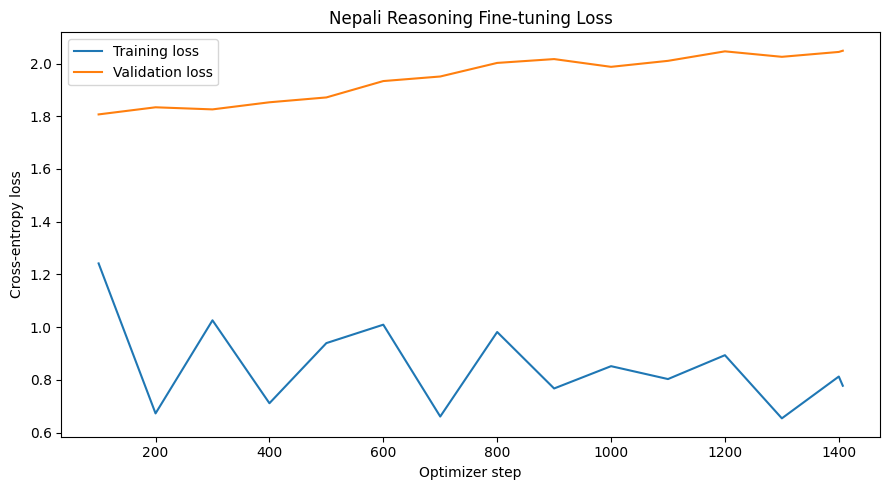

In [16]:
if history["step"]:
    history_df_plot = pd.DataFrame(history) if "pd" in globals() else None

    plt.figure(figsize=(10, 5))
    sns.lineplot(
        x=history["step"],
        y=history["train_loss"],
        marker="o",
        label="Training loss",
    )
    sns.lineplot(
        x=history["step"],
        y=history["val_loss"],
        marker="o",
        label="Validation loss",
    )
    plt.xlabel("Optimizer step")
    plt.ylabel("Cross-entropy loss")
    plt.title(f"{INFO['name']} Fine-tuning Loss")
    plt.legend()
    plt.tight_layout()
    plt.savefig(PLOT_OUT / "finetuning_loss.png", dpi=220, bbox_inches="tight")
    plt.show()

## 10. Post-fine-tuning reasoning evaluation

Use the exact same test set and decoding procedure as the pretrained baseline.

In [17]:
finetuned_acc, finetuned_task_acc, finetuned_difficulty_acc, finetuned_records = evaluate_reasoning(test_rows)

print(f"Fine-tuned overall accuracy: {finetuned_acc * 100:.2f}%")
for task in sorted(finetuned_task_acc):
    print(f"  {task:15s}: {finetuned_task_acc[task] * 100:.2f}%")

print("\nBy difficulty:")
for diff in sorted(finetuned_difficulty_acc):
    print(f"  {diff:8s}: {finetuned_difficulty_acc[diff] * 100:.2f}%")

print("\nComparison:")
print(f"{'Metric':20s} {'Pretrained':>12s} {'Fine-tuned':>12s} {'Delta':>12s}")
print("-" * 60)
print(
    f"{'Overall accuracy':20s} "
    f"{baseline_acc * 100:11.2f}% "
    f"{finetuned_acc * 100:11.2f}% "
    f"{(finetuned_acc - baseline_acc) * 100:+11.2f} pp"
)

comparison = {}
for task in sorted(set(r["task_type"] for r in test_rows)):
    b = baseline_task_acc.get(task, 0.0)
    f = finetuned_task_acc.get(task, 0.0)
    comparison[task] = {
        "pretrained": b,
        "finetuned": f,
        "delta": f - b,
    }
    print(
        f"{task:20s} "
        f"{b * 100:11.2f}% "
        f"{f * 100:11.2f}% "
        f"{(f - b) * 100:+11.2f} pp"
    )

difficulty_comparison = {}
for diff in sorted(set(baseline_difficulty_acc) | set(finetuned_difficulty_acc)):
    b = baseline_difficulty_acc.get(diff, 0.0)
    f = finetuned_difficulty_acc.get(diff, 0.0)
    difficulty_comparison[diff] = {
        "pretrained": b,
        "finetuned": f,
        "delta": f - b,
    }
    print(
        f"{diff:20s} "
        f"{b * 100:11.2f}% "
        f"{f * 100:11.2f}% "
        f"{(f - b) * 100:+11.2f} pp"
    )

100%|██████████| 1000/1000 [00:45<00:00, 21.95it/s]

Fine-tuned overall accuracy: 2.60%
  algebra        : 0.00%
  arithmetic     : 0.00%
  common_sense   : 0.00%
  comparison     : 4.29%
  counting       : 0.00%
  logic          : 0.00%
  multi_hop      : 0.00%
  percentage     : 0.00%
  physics_density: 0.00%
  physics_fma    : 3.33%
  physics_work   : 0.00%
  ratio          : 5.71%
  speed_distance : 20.00%
  transitive     : 0.00%
  unit_conversion: 4.29%

By difficulty:
  easy    : 1.27%
  hard    : 4.18%
  medium  : 1.61%

Comparison:
Metric                 Pretrained   Fine-tuned        Delta
------------------------------------------------------------
Overall accuracy            0.20%        2.60%       +2.40 pp
algebra                     1.25%        0.00%       -1.25 pp
arithmetic                  0.00%        0.00%       +0.00 pp
common_sense                0.00%        0.00%       +0.00 pp
comparison                  0.00%        4.29%       +4.29 pp
counting                    0.00%        0.00%       +0.00 pp
logic        

In [18]:

results = {
    "language": LANG,
    "test_size": len(test_rows),
    "pretrained_accuracy": baseline_acc,
    "finetuned_accuracy": finetuned_acc,
    "absolute_accuracy_delta": finetuned_acc - baseline_acc,
    "pretrained_task_accuracy": baseline_task_acc,
    "finetuned_task_accuracy": finetuned_task_acc,
    "pretrained_difficulty_accuracy": baseline_difficulty_acc,
    "finetuned_difficulty_accuracy": finetuned_difficulty_acc,
    "task_comparison": comparison,
    "difficulty_comparison": difficulty_comparison,
    "generation_max_new_tokens": GEN_MAX_NEW_TOKENS,
}

with open(METRIC_OUT / "reasoning_results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

with open(METRIC_OUT / "baseline_predictions.jsonl", "w", encoding="utf-8") as f:
    for row in baseline_records:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

with open(METRIC_OUT / "finetuned_predictions.jsonl", "w", encoding="utf-8") as f:
    for row in finetuned_records:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

print("Saved metrics and predictions to:", METRIC_OUT)

Saved metrics and predictions to: /kaggle/working/phase3_ne/metrics


## 11. Qualitative error analysis

Show successful and failed examples before and after fine-tuning. These examples are useful in the final report because the assignment asks for qualitative successes/failures and error analysis.

In [19]:
merged = []

for b, f in zip(baseline_records, finetuned_records):
    merged.append({
        "id": b["id"],
        "task_type": b["task_type"],
        "question": next(r["question"] for r in test_rows if r["id"] == b["id"]),
        "answer": b["answer"],
        "pretrained": b["prediction"],
        "pretrained_correct": b["correct"],
        "finetuned": f["prediction"],
        "finetuned_correct": f["correct"],
    })

print("=== Improvements ===")
shown = 0
for r in merged:
    if not r["pretrained_correct"] and r["finetuned_correct"]:
        print("\n", r["task_type"])
        print("Q:", r["question"])
        print("Gold:", r["answer"])
        print("Before:", r["pretrained"])
        print("After :", r["finetuned"])
        shown += 1
        if shown >= 8:
            break

print("\n=== Remaining failures ===")
shown = 0
for r in merged:
    if not r["finetuned_correct"]:
        print("\n", r["task_type"])
        print("Q:", r["question"])
        print("Gold:", r["answer"])
        print("Before:", r["pretrained"])
        print("After :", r["finetuned"])
        shown += 1
        if shown >= 8:
            break

=== Improvements ===

 ratio
Q: राम और मोहन की उम्र का अनुपात 2:5 है। यदि राम की उम्र 12 वर्ष है, तो मोहन की उम्र कितनी है?
Gold: 30
Before: 2 : 2 : 2 : 2 :
After : 30 55555555555555

 comparison
Q: मोबाइल का मान 42 है और साइकिल का मान 52 है। इनमें से छोटा कौन है?
Gold: मोबाइल
Before: 2 9 8 मा , यो एक सानो
After : मोबाइल का 428 र 688888

 speed_distance
Q: एक कार 50 किलोमीटर प्रति घंटा की गति से चलती है। 5 घंटे में वह कितनी दूरी तय करेगी?
Gold: 250
Before: 5 किलोमीटर प्रति घण्टा प्रति घण्टा प्रति घण्टा
After : 250 000 किलो प्रति 20000 प्रति 20000

 speed_distance
Q: एक कार 30 किलोमीटर प्रति घंटा की गति से चलती है। 1 घंटे में वह कितनी दूरी तय करेगी?
Gold: 30
Before: 2 9 मिमी को एक ठूलो भाग को
After : 30 किलो प्रति 12000 प्रति 100 प्रति

 ratio
Q: राजू और माया की उम्र का अनुपात 3:5 है। यदि राजू की उम्र 48 वर्ष है, तो माया की उम्र कितनी है?
Gold: 80
Before: 2 : 2 : 2 : 2 :
After : 80 55555555555555

 physics_fma
Q: यदि 10 किलोग्राम की वस्तु का त्वरण 3 मीटर प्रति सेकंड वर्ग से दोगुना हो जा

## 12. Attention analysis

The supplied model returns one attention tensor per Transformer block when `return_attention=True`.

We compare:

- one early layer
- one late layer
- multiple heads
- pretrained vs. fine-tuned

We also compute:

\[
H = -\sum_j p_j \log p_j
\]

for attention entropy, and

\[
D = \sum_j p_j |i-j|
\]

for mean attention distance.

Higher entropy indicates more diffuse attention. Larger mean distance indicates more long-range attention.

In [20]:
def attention_stats(attn):

    p = attn.clamp_min(1e-12)

    entropy = -(p * p.log()).sum(dim=-1)

    T = attn.size(-1)
    positions = torch.arange(T, device=attn.device)
    distance = (positions[None, :] - positions[:, None]).abs().float()
    mean_distance = (attn * distance).sum(dim=-1)

    return (
        entropy.mean(dim=(0, 2)).detach().cpu().numpy(),
        mean_distance.mean(dim=(0, 2)).detach().cpu().numpy(),
    )

def get_attention_for_row(model_obj, row):
    prompt, _ = format_example(row)
    ids = encode_text(prompt)

    ids = ids[-CONTEXT_LEN:]
    x = torch.tensor([ids], dtype=torch.long, device=DEVICE)

    model_obj.eval()
    with torch.no_grad():
        with torch.autocast(
            device_type=DEVICE.type,
            dtype=amp_dtype,
            enabled=use_amp,
        ):
            _, _, maps = model_obj(
                x,
                return_attention=True,
            )

    return ids, maps

def reload_model_checkpoint(path):
    ck = torch.load(path, map_location="cpu")
    m = GPTLanguageModel(
        vocab_size=CKPT_VOCAB_SIZE,
        d_model=D_MODEL,
        n_heads=N_HEADS,
        n_layers=N_LAYERS,
        d_ff=D_FF,
        context_len=CONTEXT_LEN,
        dropout=0.1,
        pad_token_id=PAD_ID,
    )
    m.load_state_dict(ck["model"], strict=True)
    return m.to(DEVICE)


pretrained_model = reload_model_checkpoint(CKPT_PATH)
finetuned_model = reload_model_checkpoint(CKPT_OUT / "final.pt")

attention_row = test_rows[0]
print("Attention example:")
print(attention_row["question"])
print("Gold:", attention_row["answer"])

Attention example:
एक मशीन 26 वाट की शक्ति से 26 सेकंड चलती है। उसने कितना कार्य किया?
Gold: 676


/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2357 (\N{DEVANAGARI LETTER VA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2335 (\N{DEVANAGARI LETTER TTA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipyk

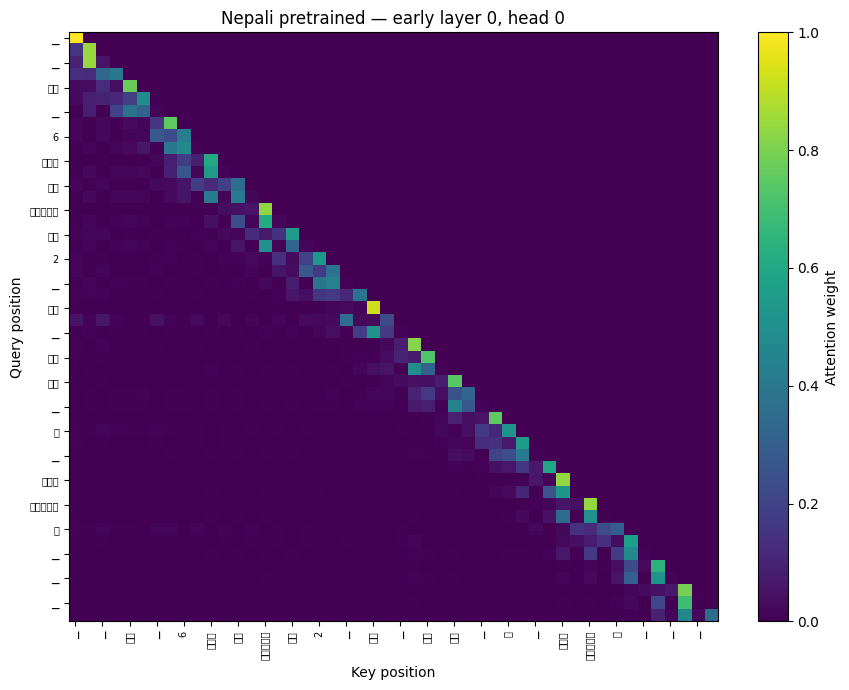

/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2357 (\N{DEVANAGARI LETTER VA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2335 (\N{DEVANAGARI LETTER TTA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipyk

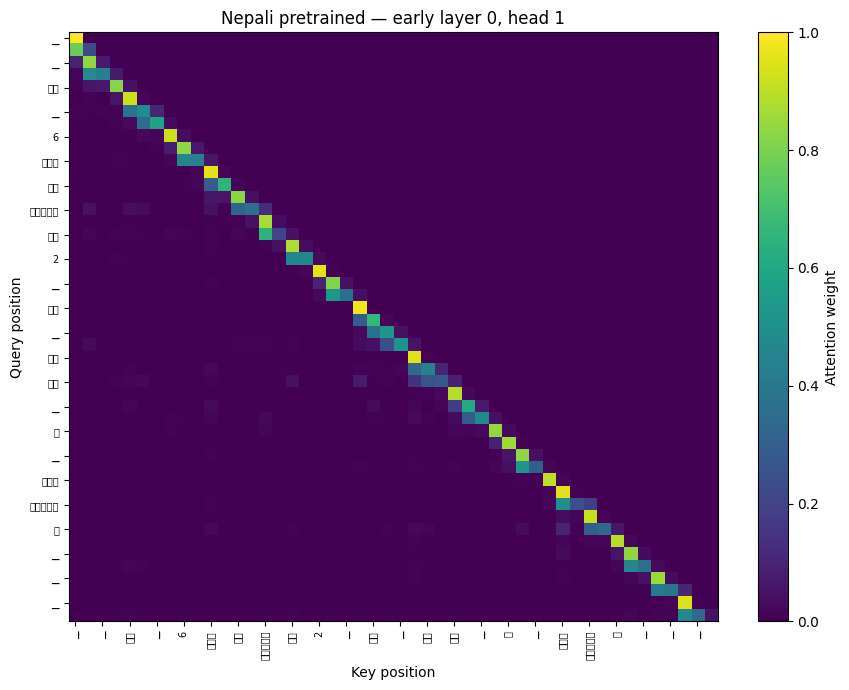

/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2357 (\N{DEVANAGARI LETTER VA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2335 (\N{DEVANAGARI LETTER TTA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipyk

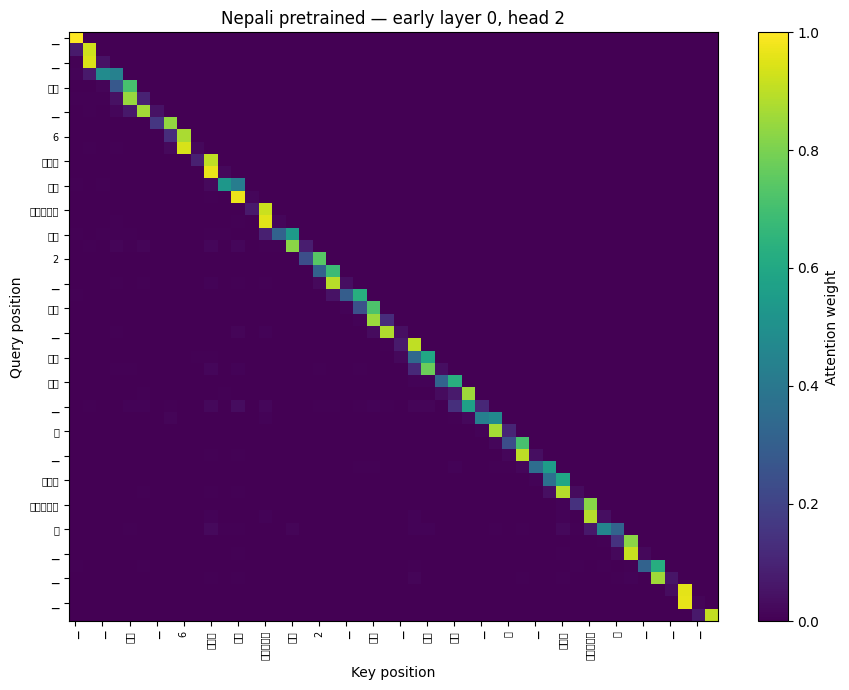

/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2357 (\N{DEVANAGARI LETTER VA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2335 (\N{DEVANAGARI LETTER TTA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipyk

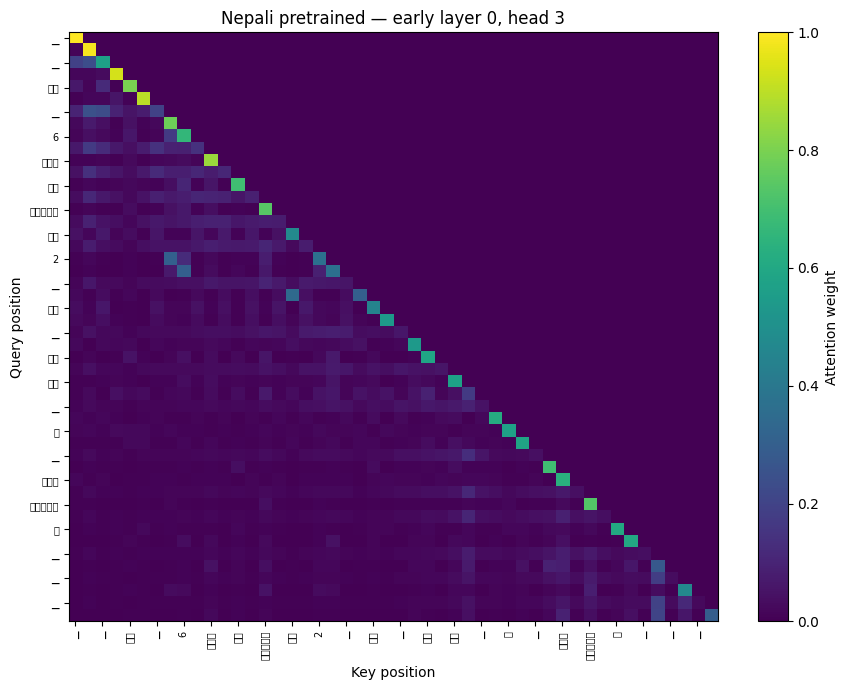

/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2357 (\N{DEVANAGARI LETTER VA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2335 (\N{DEVANAGARI LETTER TTA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipyk

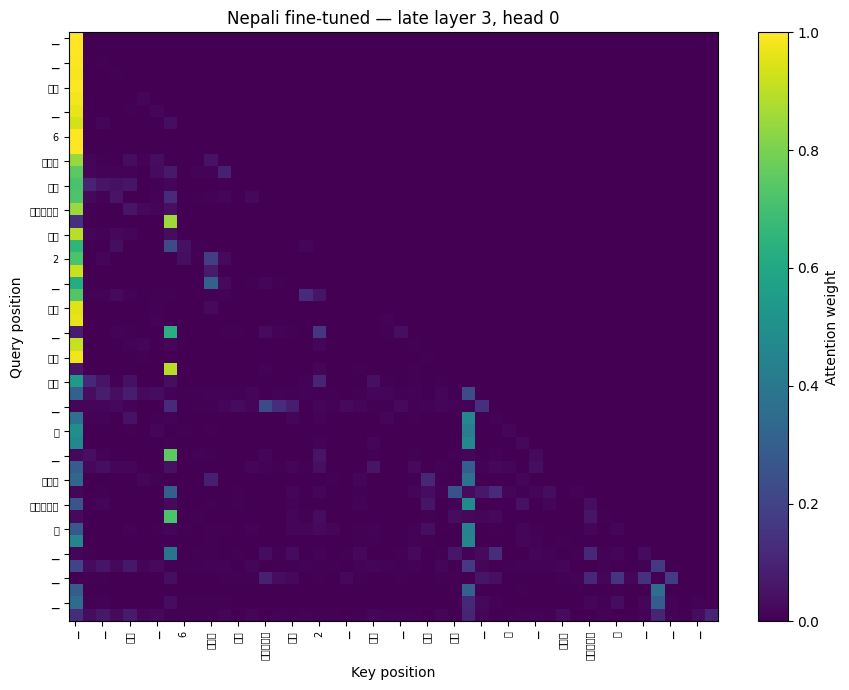

/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2357 (\N{DEVANAGARI LETTER VA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2335 (\N{DEVANAGARI LETTER TTA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipyk

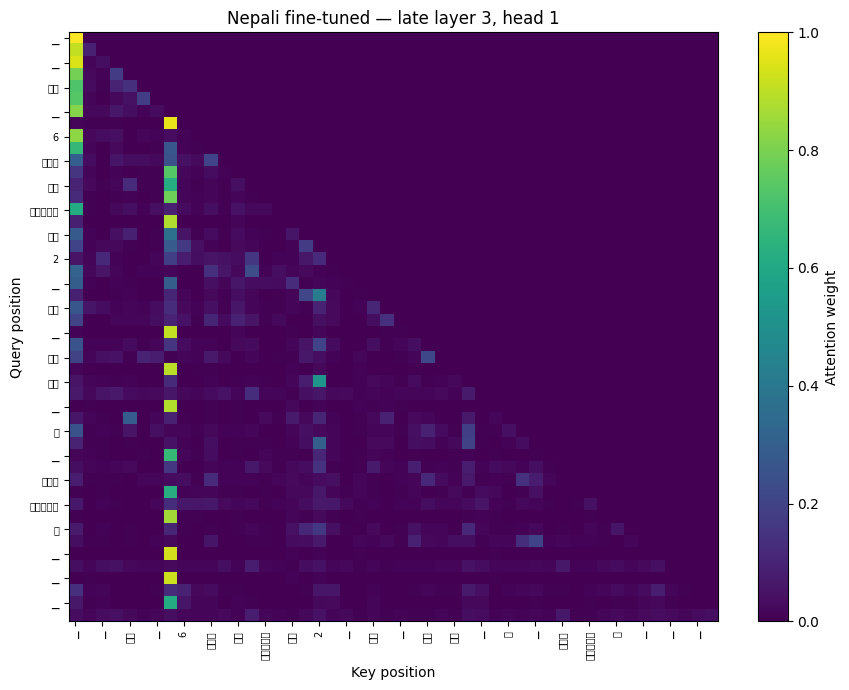

/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2357 (\N{DEVANAGARI LETTER VA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2335 (\N{DEVANAGARI LETTER TTA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipyk

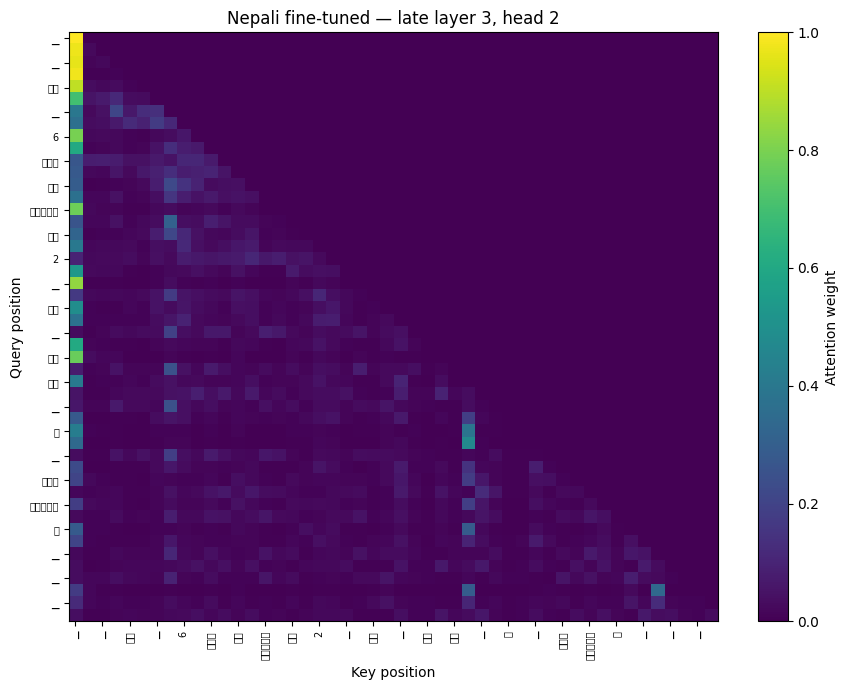

/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2357 (\N{DEVANAGARI LETTER VA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2335 (\N{DEVANAGARI LETTER TTA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2181525150.py:32: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipyk

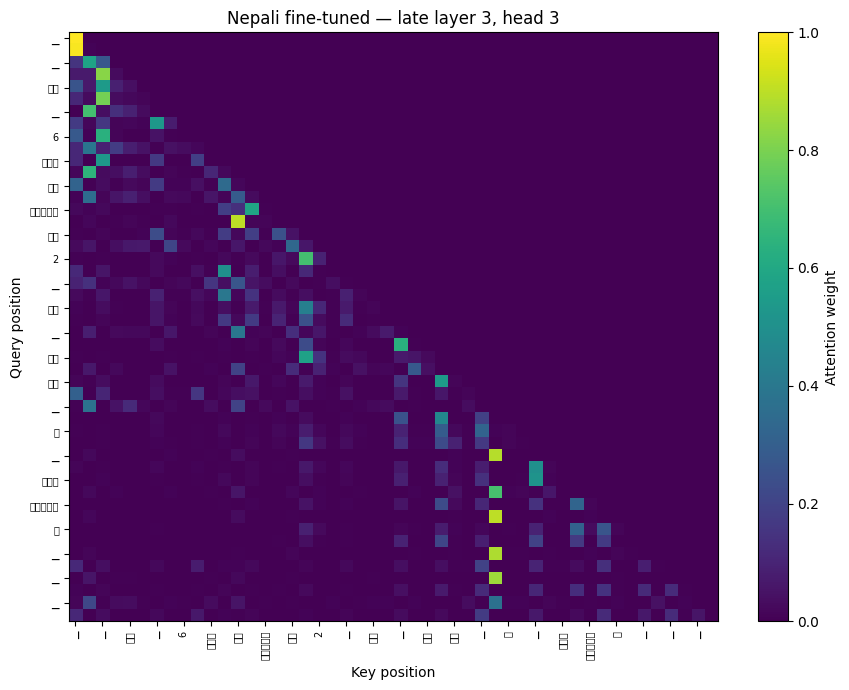

In [21]:
def token_labels(ids):
    labels = []
    for i in ids:
        labels.append(ID_TO_TOKEN.get(int(i), "?"))
    return labels

def plot_attention(model_obj, row, layer_idx, head_idx, title, filename):
    ids, maps = get_attention_for_row(model_obj, row)
    layer_idx = min(layer_idx, len(maps) - 1)

    attn = maps[layer_idx][0].detach().float().cpu()



    matrix = attn[head_idx].numpy()

    labels = token_labels(ids)

    plt.figure(figsize=(9, 7))
    plt.imshow(matrix, aspect="auto")
    plt.colorbar(label="Attention weight")
    plt.xlabel("Key position")
    plt.ylabel("Query position")
    plt.title(title)

    n = len(labels)
    step = max(1, n // 20)
    ticks = list(range(0, n, step))
    plt.xticks(ticks, [labels[i] for i in ticks], rotation=90, fontsize=7)
    plt.yticks(ticks, [labels[i] for i in ticks], fontsize=7)

    plt.tight_layout()
    plt.savefig(PLOT_OUT / filename, dpi=180)
    plt.show()

early_layer = 0
late_layer = N_LAYERS - 1

for head in range(min(4, N_HEADS)):
    plot_attention(
        pretrained_model,
        attention_row,
        early_layer,
        head,
        f"{INFO['name']} pretrained — early layer {early_layer}, head {head}",
        f"pretrained_early_L{early_layer}_H{head}.png",
    )

for head in range(min(4, N_HEADS)):
    plot_attention(
        finetuned_model,
        attention_row,
        late_layer,
        head,
        f"{INFO['name']} fine-tuned — late layer {late_layer}, head {head}",
        f"finetuned_late_L{late_layer}_H{head}.png",
    )

In [22]:

N_ATTENTION_SAMPLES = min(32, len(test_rows))

def aggregate_attention_metrics(model_obj, rows):
    entropies = []
    distances = []

    for row in rows:
        _, maps = get_attention_for_row(model_obj, row)

        layer_ent = []
        layer_dist = []

        for attn in maps:
            e, d = attention_stats(attn.float())
            layer_ent.append(e)
            layer_dist.append(d)

        entropies.append(np.stack(layer_ent))
        distances.append(np.stack(layer_dist))

    return np.mean(entropies, axis=0), np.mean(distances, axis=0)

pre_e, pre_d = aggregate_attention_metrics(
    pretrained_model,
    test_rows[:N_ATTENTION_SAMPLES],
)
ft_e, ft_d = aggregate_attention_metrics(
    finetuned_model,
    test_rows[:N_ATTENTION_SAMPLES],
)


attention_summary = {
    "pretrained_entropy": pre_e.tolist(),
    "pretrained_mean_distance": pre_d.tolist(),
    "finetuned_entropy": ft_e.tolist(),
    "finetuned_mean_distance": ft_d.tolist(),
}

with open(METRIC_OUT / "attention_summary.json", "w", encoding="utf-8") as f:
    json.dump(attention_summary, f, indent=2)

print("Layer/head attention summary")
for layer in range(N_LAYERS):
    print(
        f"L{layer}: "
        f"pre entropy={pre_e[layer].mean():.4f}, "
        f"ft entropy={ft_e[layer].mean():.4f}, "
        f"pre distance={pre_d[layer].mean():.4f}, "
        f"ft distance={ft_d[layer].mean():.4f}"
    )

Layer/head attention summary
L0: pre entropy=1.2557, ft entropy=1.2657, pre distance=3.2401, ft distance=3.4914
L1: pre entropy=2.4274, ft entropy=2.3484, pre distance=9.5667, ft distance=10.4112
L2: pre entropy=1.9054, ft entropy=2.0172, pre distance=9.3454, ft distance=10.2814
L3: pre entropy=1.7281, ft entropy=1.7188, pre distance=13.4459, ft distance=13.7714


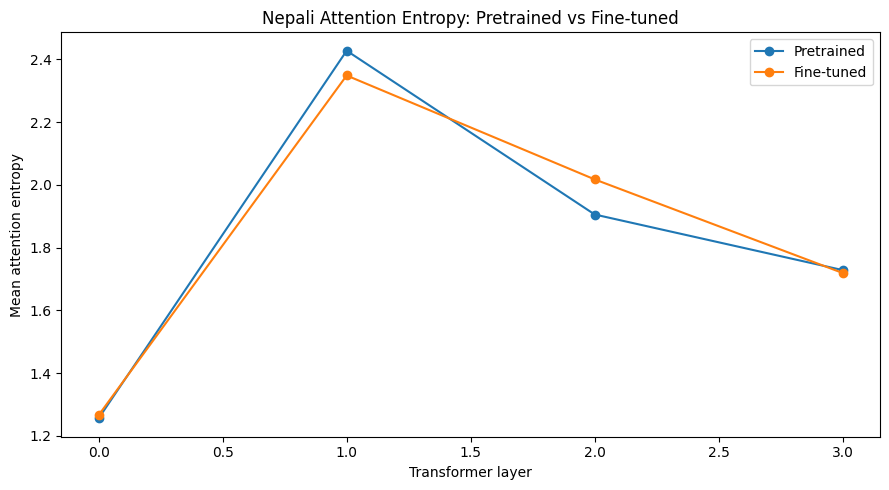

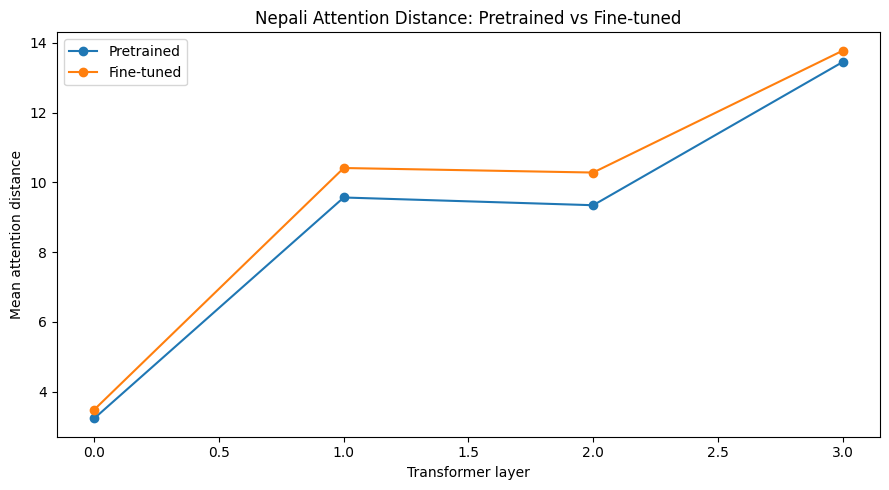

In [23]:

layers = np.arange(N_LAYERS)

plt.figure(figsize=(9, 5))
plt.plot(layers, pre_e.mean(axis=1), marker="o", label="Pretrained")
plt.plot(layers, ft_e.mean(axis=1), marker="o", label="Fine-tuned")
plt.xlabel("Transformer layer")
plt.ylabel("Mean attention entropy")
plt.title(f"{INFO['name']} Attention Entropy: Pretrained vs Fine-tuned")
plt.legend()
plt.tight_layout()
plt.savefig(PLOT_OUT / "attention_entropy_comparison.png", dpi=180)
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(layers, pre_d.mean(axis=1), marker="o", label="Pretrained")
plt.plot(layers, ft_d.mean(axis=1), marker="o", label="Fine-tuned")
plt.xlabel("Transformer layer")
plt.ylabel("Mean attention distance")
plt.title(f"{INFO['name']} Attention Distance: Pretrained vs Fine-tuned")
plt.legend()
plt.tight_layout()
plt.savefig(PLOT_OUT / "attention_distance_comparison.png", dpi=180)
plt.show()

## 13. Final artifact summary

Everything needed for Phase 3 is now under:

```text
/kaggle/working/phase3_<lang>/
├── checkpoints/
│   ├── step_*.pt
│   ├── last.pt
│   └── final.pt
├── metrics/
│   ├── reasoning_results.json
│   ├── baseline_predictions.jsonl
│   ├── finetuned_predictions.jsonl
│   └── attention_summary.json
├── plots/
│   ├── finetuning_loss.png
│   ├── attention_entropy_comparison.png
│   ├── attention_distance_comparison.png
│   └── attention heatmaps...
├── logs/
├── src/
│   ├── model.py
│   └── tokenizers.py
└── finetune_config.json

In [24]:
print("Phase 3 artifacts:")
for path in sorted(OUT.rglob("*")):
    if path.is_file():
        print(f"{path.relative_to(OUT)}  ({path.stat().st_size / 1024:.1f} KB)")

print("\nFINAL RESULT")
print(f"Language: {INFO['name']}")
print(f"Pretrained accuracy: {baseline_acc * 100:.2f}%")
print(f"Fine-tuned accuracy: {finetuned_acc * 100:.2f}%")
print(f"Improvement: {(finetuned_acc - baseline_acc) * 100:+.2f} percentage points")

print("\nSaved PNG plots:")
for p in sorted(PLOT_OUT.glob("*.png")):
    print(" ", p.name)

print("\nHugging Face:")
if HF_PUSH_ENABLED:
    print("Repository:", HF_REPO_ID)
    print("Checkpoint uploads: enabled")
else:
    print("Checkpoint uploads: disabled because HF_TOKEN is not set.")

Phase 3 artifacts:
checkpoints/final.pt  (285814.7 KB)
checkpoints/last.pt  (285814.4 KB)
checkpoints/step_000100.pt  (285828.9 KB)
checkpoints/step_000200.pt  (285828.9 KB)
checkpoints/step_000300.pt  (285828.9 KB)
checkpoints/step_000400.pt  (285829.0 KB)
checkpoints/step_000500.pt  (285829.0 KB)
checkpoints/step_000600.pt  (285829.1 KB)
checkpoints/step_000700.pt  (285829.1 KB)
checkpoints/step_000800.pt  (285829.1 KB)
checkpoints/step_000900.pt  (285829.1 KB)
checkpoints/step_001000.pt  (285829.2 KB)
checkpoints/step_001100.pt  (285829.2 KB)
checkpoints/step_001200.pt  (285829.2 KB)
checkpoints/step_001300.pt  (285829.2 KB)
checkpoints/step_001400.pt  (285829.3 KB)
checkpoints/step_001407.pt  (285829.3 KB)
finetune_config.json  (0.3 KB)
metrics/attention_summary.json  (1.9 KB)
metrics/baseline_predictions.jsonl  (188.9 KB)
metrics/finetuned_predictions.jsonl  (185.4 KB)
metrics/reasoning_results.json  (3.3 KB)
plots/attention_distance_comparison.png  (80.1 KB)
plots/attention_entro


# 14. Phase 3 deliverables: consolidated tables and plots

This section consolidates the Phase 3 evidence into notebook-visible tables and saved
artifacts. It covers the required reasoning dataset statistics, finetuning configuration
and logs, pretrained-vs-finetuned reasoning results, qualitative error analysis, and
post-finetuning attention analysis.

All generated tables are also saved as CSV files under `metrics/tables/`, while figures
are saved under `plots/`. This keeps the graded evidence inside the notebook/artifact
directory as required by the project specification.


In [25]:


import pandas as pd
import seaborn as sns
from IPython.display import display

TABLE_OUT = METRIC_OUT / "tables"
TABLE_OUT.mkdir(parents=True, exist_ok=True)

sns.set_theme(context="notebook", style="whitegrid")

def save_display_table(df, name, index=False, percent_cols=None):
    """Save a reporting DataFrame to CSV and display it in the notebook."""
    out = df.copy()
    if percent_cols:
        for col in percent_cols:
            if col in out.columns:
                out[col] = out[col] * 100.0
    out.to_csv(TABLE_OUT / f"{name}.csv", index=index)
    display(out)
    return out

## 14.0 Final result plots

The following figures are the final report-ready plots. Every figure is saved as a PNG under `plots/`.


In [ ]:



if history["step"]:
    plt.figure(figsize=(10, 5))
    sns.lineplot(x=history["step"], y=history["train_loss"], marker="o", label="Train")
    sns.lineplot(x=history["step"], y=history["val_loss"], marker="o", label="Validation")
    plt.xlabel("Optimizer step")
    plt.ylabel("Cross-entropy loss")
    plt.title(f"{INFO['name']} SFT Training Curve")
    plt.legend()
    plt.tight_layout()
    plt.savefig(PLOT_OUT / "final_training_validation_loss.png", dpi=220, bbox_inches="tight")
    plt.show()


overall_plot_df = pd.DataFrame({
    "model_state": ["Pretrained", "Fine-tuned"],
    "accuracy": [baseline_acc, finetuned_acc],
})
plt.figure(figsize=(7, 5))
sns.barplot(data=overall_plot_df, x="model_state", y="accuracy")
plt.ylim(0, 1)
plt.ylabel("Exact-match accuracy")
plt.xlabel("")
plt.title(f"{INFO['name']} Overall Reasoning Accuracy")
plt.tight_layout()
plt.savefig(PLOT_OUT / "final_overall_accuracy.png", dpi=220, bbox_inches="tight")
plt.show()


task_plot = task_results_df.melt(
    id_vars="task_type",
    value_vars=["pretrained", "finetuned"],
    var_name="model_state",
    value_name="accuracy",
)
plt.figure(figsize=(13, 6))
sns.barplot(data=task_plot, x="task_type", y="accuracy", hue="model_state")
plt.ylim(0, 1)
plt.xlabel("Task type")
plt.ylabel("Exact-match accuracy")
plt.title(f"{INFO['name']} Reasoning Accuracy by Task")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Model state")
plt.tight_layout()
plt.savefig(PLOT_OUT / "final_accuracy_by_task.png", dpi=220, bbox_inches="tight")
plt.show()


layers = np.arange(N_LAYERS)
plt.figure(figsize=(9, 5))
sns.lineplot(x=layers, y=pre_d.mean(axis=1), marker="o", label="Pretrained")
sns.lineplot(x=layers, y=ft_d.mean(axis=1), marker="o", label="Fine-tuned")
plt.xlabel("Transformer layer")
plt.ylabel("Mean attention distance")
plt.title(f"{INFO['name']} Attention Distance by Layer")
plt.legend()
plt.tight_layout()
plt.savefig(PLOT_OUT / "final_attention_distance.png", dpi=220, bbox_inches="tight")
plt.show()

print("\nFinal PNG figures saved to:", PLOT_OUT)

## 14.1 Reasoning dataset tables

In [26]:


split_rows = []
for split_name, rows in [
    ("train", train_rows),
    ("validation", val_rows),
    ("test", test_rows),
]:
    answer_lengths = [answer_token_length(r["answer"]) for r in rows]
    split_rows.append({
        "split": split_name,
        "examples": len(rows),
        "task_types": len(set(r["task_type"] for r in rows)),
        "templates": len(set(r["template_id"] for r in rows)),
        "mean_answer_tokens": float(np.mean(answer_lengths)),
        "max_answer_tokens": int(np.max(answer_lengths)),
    })

dataset_summary_df = pd.DataFrame(split_rows)
save_display_table(dataset_summary_df, "dataset_split_summary")


task_names = sorted(set(r["task_type"] for r in train_rows + val_rows + test_rows))
task_rows = []
for task in task_names:
    row = {"task_type": task}
    for split_name, rows in [
        ("train", train_rows), ("validation", val_rows), ("test", test_rows)
    ]:
        row[split_name] = sum(r["task_type"] == task for r in rows)
    task_rows.append(row)

task_distribution_df = pd.DataFrame(task_rows)
save_display_table(task_distribution_df, "task_distribution")


difficulty_names = sorted(set(
    r.get("difficulty")
    for r in train_rows + val_rows + test_rows
    if r.get("difficulty") is not None
))
difficulty_rows = []
for difficulty in difficulty_names:
    row = {"difficulty": difficulty}
    for split_name, rows in [
        ("train", train_rows), ("validation", val_rows), ("test", test_rows)
    ]:
        row[split_name] = sum(r.get("difficulty") == difficulty for r in rows)
    difficulty_rows.append(row)

difficulty_distribution_df = pd.DataFrame(difficulty_rows)
save_display_table(difficulty_distribution_df, "difficulty_distribution")


template_rows = []
for split_name, rows in [
    ("train", train_rows), ("validation", val_rows), ("test", test_rows)
]:
    counts = Counter(r["template_id"] for r in rows)
    for template_id, count in sorted(counts.items()):
        template_rows.append({
            "split": split_name,
            "template_id": template_id,
            "examples": count,
        })

template_coverage_df = pd.DataFrame(template_rows)
save_display_table(template_coverage_df, "template_coverage")

,split,examples,task_types,templates,mean_answer_tokens,max_answer_tokens
0,train,15000,15,22,3.195933,13
1,validation,2000,15,15,2.801000,5
2,test,1000,15,25,2.963000,11


,task_type,train,validation,test
0,algebra,1200,160,80
1,arithmetic,1050,140,70
2,common_sense,1050,140,70
3,comparison,1050,140,70
4,counting,600,80,40
5,logic,1050,140,70
6,multi_hop,1350,180,90
7,percentage,1050,140,70
8,physics_density,750,100,50
9,physics_fma,900,120,60


,difficulty,train,validation,test
0,easy,4497,506,157
1,hard,3052,482,407
2,medium,7451,1012,436


,split,template_id,examples
0,train,alg1,615
1,train,alg2,585
2,train,arith1,561
3,train,arith2,489
4,train,cmp1,517
...,...,...,...
57,test,spd4,33
58,test,tr4,70
59,test,unit4,33
60,test,unit5,37


,split,template_id,examples
0,train,alg1,615
1,train,alg2,585
2,train,arith1,561
3,train,arith2,489
4,train,cmp1,517
...,...,...,...
57,test,spd4,33
58,test,tr4,70
59,test,unit4,33
60,test,unit5,37


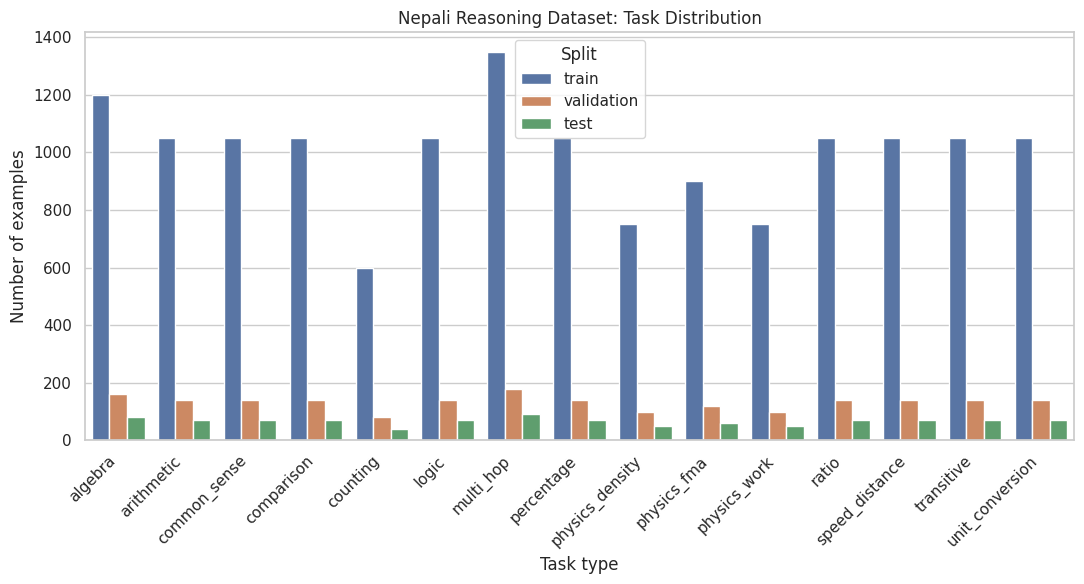

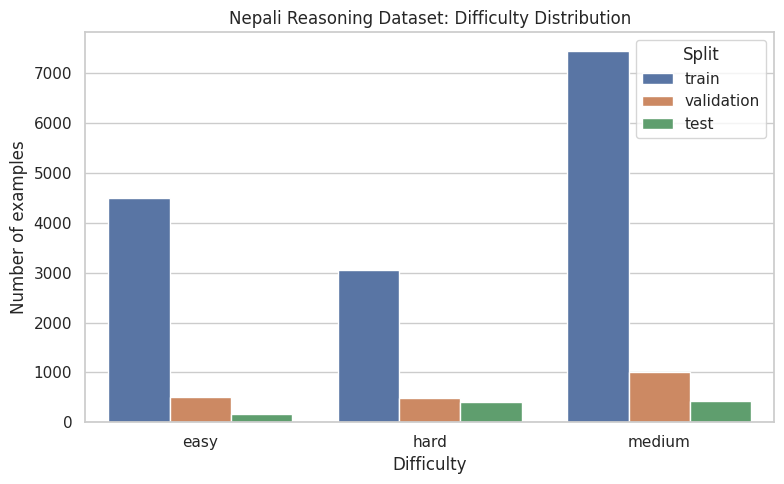

In [27]:


plt.figure(figsize=(11, 6))
plot_df = task_distribution_df.melt(
    id_vars="task_type",
    value_vars=["train", "validation", "test"],
    var_name="split",
    value_name="examples",
)
sns.barplot(data=plot_df, x="task_type", y="examples", hue="split")
plt.xlabel("Task type")
plt.ylabel("Number of examples")
plt.title(f"{INFO['name']} Reasoning Dataset: Task Distribution")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Split")
plt.tight_layout()
plt.savefig(PLOT_OUT / "phase3_task_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 5))
plot_df = difficulty_distribution_df.melt(
    id_vars="difficulty",
    value_vars=["train", "validation", "test"],
    var_name="split",
    value_name="examples",
)
sns.barplot(data=plot_df, x="difficulty", y="examples", hue="split")
plt.xlabel("Difficulty")
plt.ylabel("Number of examples")
plt.title(f"{INFO['name']} Reasoning Dataset: Difficulty Distribution")
plt.legend(title="Split")
plt.tight_layout()
plt.savefig(PLOT_OUT / "phase3_difficulty_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

## 14.2 Model and finetuning configuration

In [28]:

model_config_rows = [
    ("Language", INFO["name"]),
    ("Vocabulary size", CKPT_VOCAB_SIZE),
    ("Model dimension", D_MODEL),
    ("Attention heads", N_HEADS),
    ("Transformer layers", N_LAYERS),
    ("FFN dimension", D_FF),
    ("Context length", CONTEXT_LEN),
    ("Trainable parameters", sum(p.numel() for p in model.parameters())),
    ("Pretrained checkpoint", str(CKPT_PATH)),
    ("Finetuning epochs", FT_CONFIG["epochs"]),
    ("Batch size", FT_CONFIG["batch_size"]),
    ("Gradient accumulation", FT_CONFIG["gradient_accumulation"]),
    ("Learning rate", FT_CONFIG["learning_rate"]),
    ("Minimum learning rate", FT_CONFIG["min_learning_rate"]),
    ("Warmup ratio", FT_CONFIG["warmup_ratio"]),
    ("Weight decay", FT_CONFIG["weight_decay"]),
    ("Gradient clip", FT_CONFIG["grad_clip"]),
    ("Evaluation interval (steps)", FT_CONFIG["eval_every_steps"]),
    ("Checkpoint interval (steps)", FT_CONFIG["checkpoint_every_steps"]),
    ("HF repository", HF_REPO_ID),
]
model_config_df = pd.DataFrame(model_config_rows, columns=["parameter", "value"])
save_display_table(model_config_df, "model_finetune_config")

,parameter,value
0,Language,Nepali
1,Vocabulary size,14223
2,Model dimension,576
3,Attention heads,4
4,Transformer layers,4
5,FFN dimension,2304
6,Context length,256
7,Trainable parameters,24296256
8,Pretrained checkpoint,/kaggle/input/notebooks/gulgulasaur/lma-nepali...
9,Finetuning epochs,3


,parameter,value
0,Language,Nepali
1,Vocabulary size,14223
2,Model dimension,576
3,Attention heads,4
4,Transformer layers,4
5,FFN dimension,2304
6,Context length,256
7,Trainable parameters,24296256
8,Pretrained checkpoint,/kaggle/input/notebooks/gulgulasaur/lma-nepali...
9,Finetuning epochs,3


## 14.3 Finetuning logs and loss

,step,epoch,train_loss,val_loss,lr,val_ppl
0,100,1,1.241785,1.806929,0.000050,6.091710
1,200,1,0.672820,1.833912,0.000049,6.258322
2,300,1,1.025963,1.825980,0.000047,6.208874
3,400,1,0.711438,1.852930,0.000044,6.378479
4,500,2,0.939496,1.871319,0.000040,6.496863
5,600,2,1.009382,1.933413,0.000035,6.913064
6,700,2,0.661006,1.950714,0.000030,7.033708
7,800,2,0.981611,2.002249,0.000024,7.405694
8,900,2,0.767438,2.016793,0.000019,7.514186
9,1000,3,0.852027,1.987365,0.000015,7.296282


,final_step,final_train_loss,final_val_loss,final_val_ppl,best_step,best_val_loss,best_val_ppl
0,1407,0.777702,2.048517,7.756392,100,1.806929,6.09171


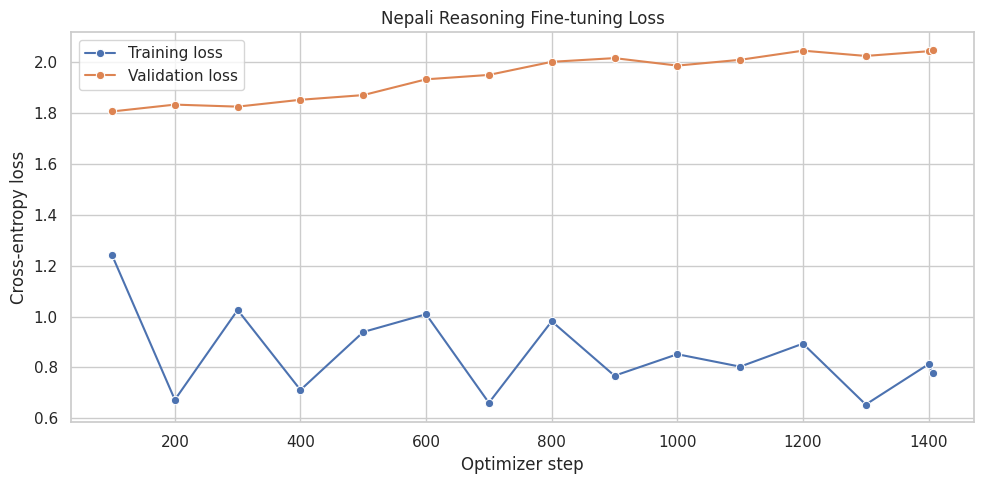

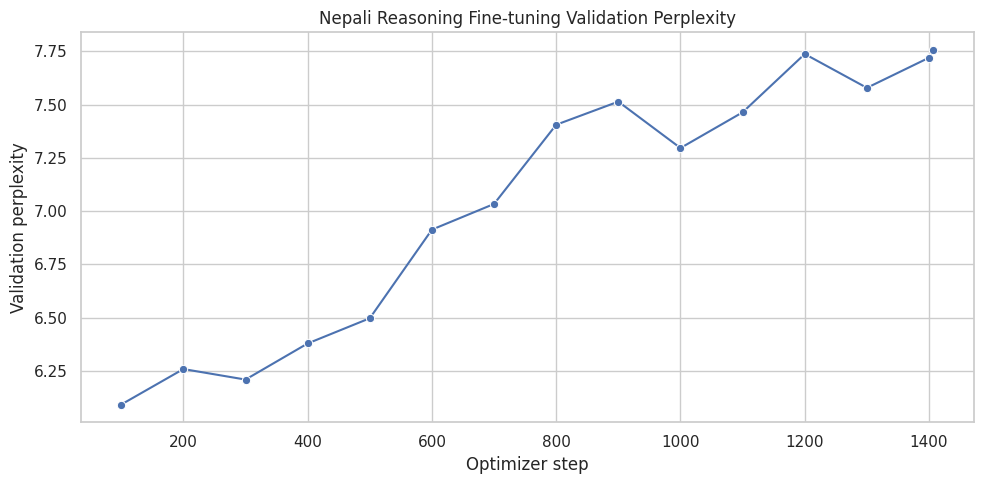

In [29]:

history_df = pd.DataFrame(history)

if not history_df.empty:
    history_df["val_ppl"] = np.exp(np.minimum(history_df["val_loss"], 20))
    save_display_table(history_df, "finetuning_history")

    best_idx = history_df["val_loss"].idxmin()
    training_summary_df = pd.DataFrame([{
        "final_step": int(history_df["step"].iloc[-1]),
        "final_train_loss": float(history_df["train_loss"].iloc[-1]),
        "final_val_loss": float(history_df["val_loss"].iloc[-1]),
        "final_val_ppl": float(history_df["val_ppl"].iloc[-1]),
        "best_step": int(history_df.loc[best_idx, "step"]),
        "best_val_loss": float(history_df.loc[best_idx, "val_loss"]),
        "best_val_ppl": float(history_df.loc[best_idx, "val_ppl"]),
    }])
    save_display_table(training_summary_df, "finetuning_summary")

    plt.figure(figsize=(10, 5))
    sns.lineplot(data=history_df, x="step", y="train_loss", marker="o", label="Training loss")
    sns.lineplot(data=history_df, x="step", y="val_loss", marker="o", label="Validation loss")
    plt.xlabel("Optimizer step")
    plt.ylabel("Cross-entropy loss")
    plt.title(f"{INFO['name']} Reasoning Fine-tuning Loss")
    plt.legend()
    plt.tight_layout()
    plt.savefig(PLOT_OUT / "phase3_finetuning_loss.png", dpi=200, bbox_inches="tight")
    plt.show()

    plt.figure(figsize=(10, 5))
    sns.lineplot(data=history_df, x="step", y="val_ppl", marker="o")
    plt.xlabel("Optimizer step")
    plt.ylabel("Validation perplexity")
    plt.title(f"{INFO['name']} Reasoning Fine-tuning Validation Perplexity")
    plt.tight_layout()
    plt.savefig(PLOT_OUT / "phase3_validation_perplexity.png", dpi=200, bbox_inches="tight")
    plt.show()
else:
    print("No finetuning history is available. Run the finetuning loop first.")

## 14.4 Pretrained vs. finetuned reasoning results

In [30]:

overall_results_df = pd.DataFrame([{
    "metric": "Exact-match accuracy",
    "pretrained": baseline_acc,
    "finetuned": finetuned_acc,
    "delta": finetuned_acc - baseline_acc,
}])
save_display_table(
    overall_results_df,
    "overall_reasoning_results",
    percent_cols=["pretrained", "finetuned", "delta"],
)

task_results_rows = []
for task in sorted(set(baseline_task_acc) | set(finetuned_task_acc)):
    b = baseline_task_acc.get(task, 0.0)
    f = finetuned_task_acc.get(task, 0.0)
    task_results_rows.append({
        "task_type": task,
        "pretrained": b,
        "finetuned": f,
        "delta": f - b,
    })
task_results_df = pd.DataFrame(task_results_rows)
save_display_table(
    task_results_df,
    "reasoning_accuracy_by_task",
    percent_cols=["pretrained", "finetuned", "delta"],
)

difficulty_results_rows = []
for difficulty in sorted(set(baseline_difficulty_acc) | set(finetuned_difficulty_acc)):
    b = baseline_difficulty_acc.get(difficulty, 0.0)
    f = finetuned_difficulty_acc.get(difficulty, 0.0)
    difficulty_results_rows.append({
        "difficulty": difficulty,
        "pretrained": b,
        "finetuned": f,
        "delta": f - b,
    })
difficulty_results_df = pd.DataFrame(difficulty_results_rows)
save_display_table(
    difficulty_results_df,
    "reasoning_accuracy_by_difficulty",
    percent_cols=["pretrained", "finetuned", "delta"],
)

,metric,pretrained,finetuned,delta
0,Exact-match accuracy,0.2,2.6,2.4


,task_type,pretrained,finetuned,delta
0,algebra,1.250000,0.000000,-1.250000
1,arithmetic,0.000000,0.000000,0.000000
2,common_sense,0.000000,0.000000,0.000000
3,comparison,0.000000,4.285714,4.285714
4,counting,0.000000,0.000000,0.000000
5,logic,0.000000,0.000000,0.000000
6,multi_hop,1.111111,0.000000,-1.111111
7,percentage,0.000000,0.000000,0.000000
8,physics_density,0.000000,0.000000,0.000000
9,physics_fma,0.000000,3.333333,3.333333


,difficulty,pretrained,finetuned,delta
0,easy,0.000000,1.273885,1.273885
1,hard,0.245700,4.176904,3.931204
2,medium,0.229358,1.605505,1.376147


,difficulty,pretrained,finetuned,delta
0,easy,0.000000,1.273885,1.273885
1,hard,0.245700,4.176904,3.931204
2,medium,0.229358,1.605505,1.376147


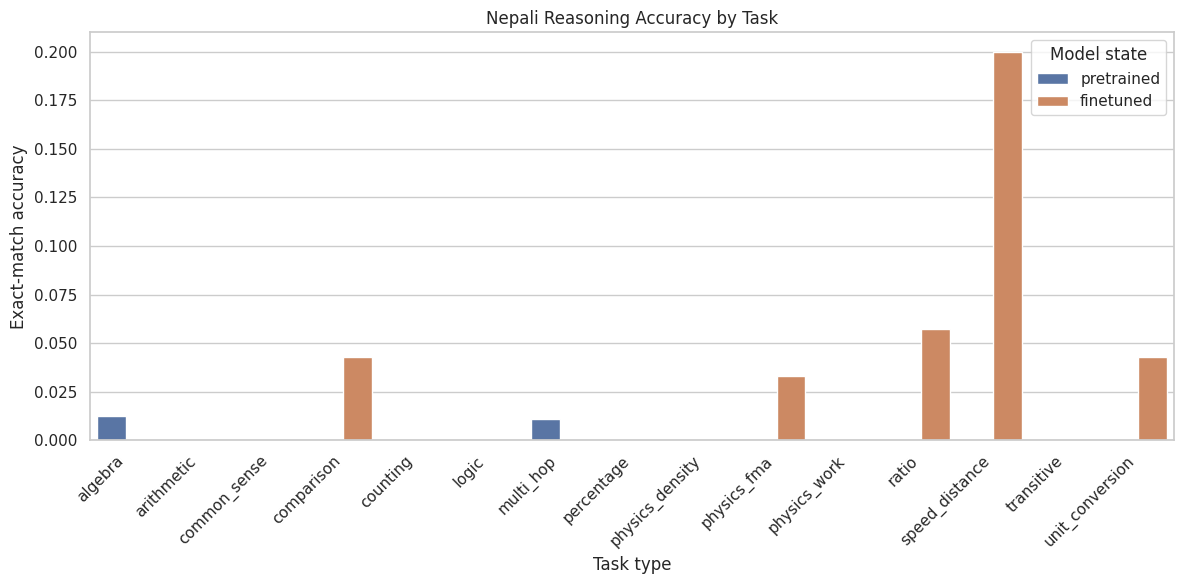

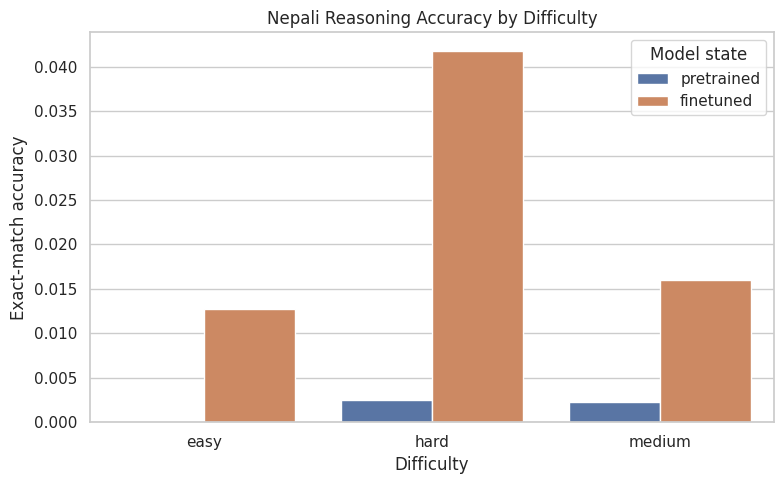

In [31]:


task_plot = task_results_df.melt(
    id_vars="task_type",
    value_vars=["pretrained", "finetuned"],
    var_name="model_state",
    value_name="accuracy",
)
plt.figure(figsize=(12, 6))
sns.barplot(data=task_plot, x="task_type", y="accuracy", hue="model_state")
plt.xlabel("Task type")
plt.ylabel("Exact-match accuracy")
plt.title(f"{INFO['name']} Reasoning Accuracy by Task")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Model state")
plt.tight_layout()
plt.savefig(PLOT_OUT / "phase3_accuracy_by_task.png", dpi=200, bbox_inches="tight")
plt.show()

difficulty_plot = difficulty_results_df.melt(
    id_vars="difficulty",
    value_vars=["pretrained", "finetuned"],
    var_name="model_state",
    value_name="accuracy",
)
plt.figure(figsize=(8, 5))
sns.barplot(data=difficulty_plot, x="difficulty", y="accuracy", hue="model_state")
plt.xlabel("Difficulty")
plt.ylabel("Exact-match accuracy")
plt.title(f"{INFO['name']} Reasoning Accuracy by Difficulty")
plt.legend(title="Model state")
plt.tight_layout()
plt.savefig(PLOT_OUT / "phase3_accuracy_by_difficulty.png", dpi=200, bbox_inches="tight")
plt.show()

## 14.5 Qualitative error analysis

In [32]:


error_category_counts = {
    "correct_before_and_after": 0,
    "improved_after_finetuning": 0,
    "regressed_after_finetuning": 0,
    "incorrect_before_and_after": 0,
}
for row in merged:
    b, f = row["pretrained_correct"], row["finetuned_correct"]
    if b and f:
        error_category_counts["correct_before_and_after"] += 1
    elif (not b) and f:
        error_category_counts["improved_after_finetuning"] += 1
    elif b and (not f):
        error_category_counts["regressed_after_finetuning"] += 1
    else:
        error_category_counts["incorrect_before_and_after"] += 1

error_summary_df = pd.DataFrame([
    {"outcome": k, "examples": v}
    for k, v in error_category_counts.items()
])
save_display_table(error_summary_df, "error_analysis_summary")


transition_rows = []
for task in sorted(set(r["task_type"] for r in merged)):
    subset = [r for r in merged if r["task_type"] == task]
    transition_rows.append({
        "task_type": task,
        "correct_before_after": sum(r["pretrained_correct"] and r["finetuned_correct"] for r in subset),
        "improved": sum((not r["pretrained_correct"]) and r["finetuned_correct"] for r in subset),
        "regressed": sum(r["pretrained_correct"] and (not r["finetuned_correct"]) for r in subset),
        "incorrect_before_after": sum((not r["pretrained_correct"]) and (not r["finetuned_correct"]) for r in subset),
    })

transition_df = pd.DataFrame(transition_rows)
save_display_table(transition_df, "error_analysis_by_task")


qualitative_df = pd.DataFrame(merged)
qualitative_df.to_csv(TABLE_OUT / "qualitative_test_predictions.csv", index=False)

print("Representative improvements:")
display(qualitative_df[
    (~qualitative_df["pretrained_correct"]) &
    (qualitative_df["finetuned_correct"])
].head(10))

print("Representative remaining failures:")
display(qualitative_df[
    (~qualitative_df["finetuned_correct"])
].head(10))

,outcome,examples
0,correct_before_and_after,0
1,improved_after_finetuning,26
2,regressed_after_finetuning,2
3,incorrect_before_and_after,972


,task_type,correct_before_after,improved,regressed,incorrect_before_after
0,algebra,0,0,1,79
1,arithmetic,0,0,0,70
2,common_sense,0,0,0,70
3,comparison,0,3,0,67
4,counting,0,0,0,40
5,logic,0,0,0,70
6,multi_hop,0,0,1,89
7,percentage,0,0,0,70
8,physics_density,0,0,0,50
9,physics_fma,0,2,0,58


Representative improvements:


,id,task_type,question,answer,pretrained,pretrained_correct,finetuned,finetuned_correct
1,hi_test_000324,ratio,राम और मोहन की उम्र का अनुपात 2:5 है। यदि राम ...,30,2 : 2 : 2 : 2 :,False,30 55555555555555,True
9,hi_test_000023,comparison,मोबाइल का मान 42 है और साइकिल का मान 52 है। इन...,मोबाइल,"2 9 8 मा , यो एक सानो",False,मोबाइल का 428 र 688888,True
28,hi_test_000525,speed_distance,एक कार 50 किलोमीटर प्रति घंटा की गति से चलती ह...,250,5 किलोमीटर प्रति घण्टा प्रति घण्टा प्रति घण्टा,False,250 000 किलो प्रति 20000 प्रति 20000,True
81,hi_test_000546,speed_distance,एक कार 30 किलोमीटर प्रति घंटा की गति से चलती ह...,30,2 9 मिमी को एक ठूलो भाग को,False,30 किलो प्रति 12000 प्रति 100 प्रति,True
85,hi_test_000330,ratio,राजू और माया की उम्र का अनुपात 3:5 है। यदि राज...,80,2 : 2 : 2 : 2 :,False,80 55555555555555,True
110,hi_test_000605,physics_fma,यदि 10 किलोग्राम की वस्तु का त्वरण 3 मीटर प्रत...,60,- - - - - - - -,False,60 किलोग्राम प्रति 20000 ग्राम प्रति 20000,True
236,hi_test_000559,speed_distance,एक कार 20 किलोमीटर प्रति घंटा की गति से चलती ह...,60,2 9 मिमी को एक ठूलो भाग को,False,60 2000 प्रति 20000 प्रति20000 प्रति200,True
258,hi_test_000510,speed_distance,एक कार 80 किलोमीटर प्रति घंटा की गति से चलती ह...,400,- 2 किलोमीटर प्रति घण्टा प्रति घण्टा प्रति,False,400 प्रति 400 प्रति 400 प्रति500,True
282,hi_test_000289,ratio,सीता और मोहन की उम्र का अनुपात 2:5 है। यदि सीत...,25,2 : 2 : 2 : 2 :,False,25 र 15 5555555555,True
389,hi_test_000560,speed_distance,एक कार 50 किलोमीटर प्रति घंटा की गति से चलती ह...,50,"1 9 5 मा , यो एक कार",False,50 000 किलो प्रति 20000 प्रति 20000,True


Representative remaining failures:


,id,task_type,question,answer,pretrained,pretrained_correct,finetuned,finetuned_correct
0,hi_test_000692,physics_work,एक मशीन 26 वाट की शक्ति से 26 सेकंड चलती है। उ...,676,28 : 28 : 28 : 2,False,3628848448888888,False
2,hi_test_000364,algebra,एक संख्या का 6 गुना करके 30 घटाने पर 24 मिलता ...,9,- 2 मिमी ; - 2 मिमी,False,5286666666666666,False
3,hi_test_000694,physics_work,एक मशीन 21 वाट की शक्ति से 19 सेकंड चलती है। उ...,399,- उत्तर : उत्तर : उत्तर : उत्तर,False,3644444444444444,False
4,hi_test_000489,unit_conversion,32 मिनट में कितने सेकंड होते हैं?,1920,"2 मिमी , 2 मिमी , 2",False,3233284444444488,False
5,hi_test_000854,logic,यदि कोई छात्र परीक्षा पास करता है तो उसे प्रमा...,नहीं,- एक परीक्षा पास ( परीक्षा पास ),False,3282828444444444,False
6,hi_test_000487,unit_conversion,70 मिनट में कितने सेकंड होते हैं?,4200,"1 9 3 मा , यो एक सानो",False,4000 टन टन टन टन टन टन टन,False
7,hi_test_000296,ratio,नंदिनी और मोहन की उम्र का अनुपात 5:2 है। यदि न...,36,2 : 2 : 2 : 2 :,False,2628444444444444,False
8,hi_test_000919,common_sense,मोबाइल की बैटरी बहुत कम है और चार्जर उपलब्ध है...,चार्जर लगाना,- एक सानो सानो सानो सानो सानो सानो,False,हाँसीहाँसीहाँसीहाँसीहाँसीहाँसीहाँसीहाँसी,False
10,hi_test_000502,speed_distance,एक धावक 50 मीटर की दूरी 10 सेकंड में तय करता ह...,5,- - - - - - - -,False,250 00 00 00 00 00 00 00,False
11,hi_test_000283,ratio,राजू और रोहित की उम्र का अनुपात 3:5 है। यदि रा...,80,2 : 2 : 2 : 2 :,False,9555555555555555,False


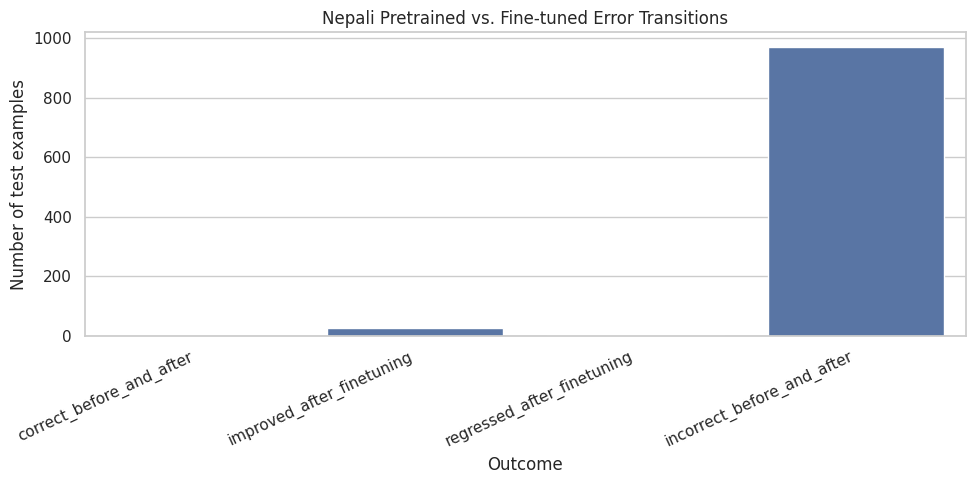

In [33]:

plt.figure(figsize=(10, 5))
sns.barplot(data=error_summary_df, x="outcome", y="examples")
plt.xlabel("Outcome")
plt.ylabel("Number of test examples")
plt.title(f"{INFO['name']} Pretrained vs. Fine-tuned Error Transitions")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(PLOT_OUT / "phase3_error_transitions.png", dpi=200, bbox_inches="tight")
plt.show()

## 14.6 Post-finetuning attention tables

In [34]:


attention_rows = []
for layer in range(N_LAYERS):
    for head in range(N_HEADS):
        attention_rows.append({
            "layer": layer,
            "head": head,
            "pretrained_entropy": float(pre_e[layer, head]),
            "finetuned_entropy": float(ft_e[layer, head]),
            "entropy_delta": float(ft_e[layer, head] - pre_e[layer, head]),
            "pretrained_mean_distance": float(pre_d[layer, head]),
            "finetuned_mean_distance": float(ft_d[layer, head]),
            "distance_delta": float(ft_d[layer, head] - pre_d[layer, head]),
        })

attention_head_df = pd.DataFrame(attention_rows)
save_display_table(attention_head_df, "attention_head_metrics")

attention_layer_rows = []
for layer in range(N_LAYERS):
    attention_layer_rows.append({
        "layer": layer,
        "pretrained_entropy_mean": float(pre_e[layer].mean()),
        "finetuned_entropy_mean": float(ft_e[layer].mean()),
        "entropy_delta": float(ft_e[layer].mean() - pre_e[layer].mean()),
        "pretrained_distance_mean": float(pre_d[layer].mean()),
        "finetuned_distance_mean": float(ft_d[layer].mean()),
        "distance_delta": float(ft_d[layer].mean() - pre_d[layer].mean()),
    })

attention_layer_df = pd.DataFrame(attention_layer_rows)
save_display_table(attention_layer_df, "attention_layer_summary")

,layer,head,pretrained_entropy,finetuned_entropy,entropy_delta,pretrained_mean_distance,finetuned_mean_distance,distance_delta
0,0,0,1.313902,1.314674,0.000773,2.426305,2.810021,0.383716
1,0,1,0.962896,1.026656,0.063759,2.274540,2.567717,0.293177
2,0,2,0.654706,0.683404,0.028698,1.248720,1.432235,0.183515
3,0,3,2.091322,2.038074,-0.053248,7.010734,7.155775,0.145041
4,1,0,2.320120,2.249186,-0.070935,8.301621,9.841940,1.540318
5,1,1,2.277102,2.351499,0.074397,5.763786,7.257407,1.493621
6,1,2,2.551601,2.251760,-0.299842,12.673390,13.210347,0.536957
7,1,3,2.560687,2.541169,-0.019518,11.527983,11.335147,-0.192836
8,2,0,1.459966,1.579972,0.120005,15.817089,15.124960,-0.692129
9,2,1,1.953805,2.180379,0.226574,4.336655,6.552267,2.215612


,layer,pretrained_entropy_mean,finetuned_entropy_mean,entropy_delta,pretrained_distance_mean,finetuned_distance_mean,distance_delta
0,0,1.255707,1.265702,0.009995,3.240075,3.491437,0.251362
1,1,2.427378,2.348403,-0.078974,9.566694,10.411210,0.844516
2,2,1.905365,2.017179,0.111815,9.345390,10.281427,0.936037
3,3,1.728085,1.718785,-0.009300,13.445916,13.771393,0.325477


,layer,pretrained_entropy_mean,finetuned_entropy_mean,entropy_delta,pretrained_distance_mean,finetuned_distance_mean,distance_delta
0,0,1.255707,1.265702,0.009995,3.240075,3.491437,0.251362
1,1,2.427378,2.348403,-0.078974,9.566694,10.411210,0.844516
2,2,1.905365,2.017179,0.111815,9.345390,10.281427,0.936037
3,3,1.728085,1.718785,-0.009300,13.445916,13.771393,0.325477


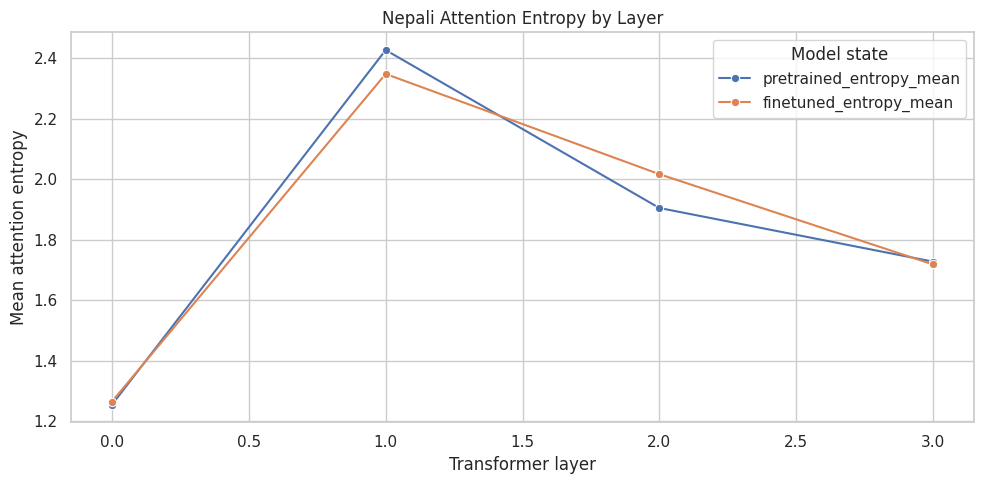

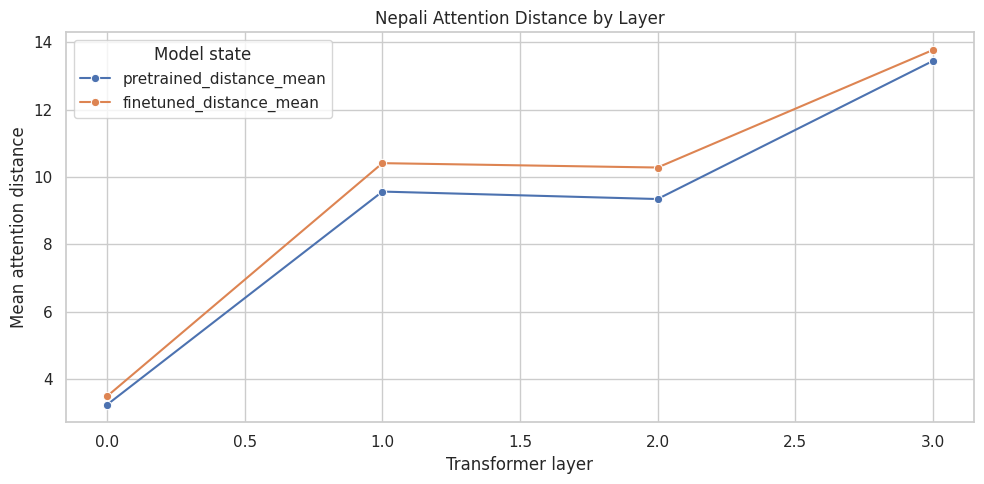

In [35]:


plt.figure(figsize=(10, 5))
entropy_plot = attention_layer_df.melt(
    id_vars="layer",
    value_vars=["pretrained_entropy_mean", "finetuned_entropy_mean"],
    var_name="model_state",
    value_name="entropy",
)
sns.lineplot(data=entropy_plot, x="layer", y="entropy", hue="model_state", marker="o")
plt.xlabel("Transformer layer")
plt.ylabel("Mean attention entropy")
plt.title(f"{INFO['name']} Attention Entropy by Layer")
plt.legend(title="Model state")
plt.tight_layout()
plt.savefig(PLOT_OUT / "phase3_attention_entropy_by_layer.png", dpi=200, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 5))
distance_plot = attention_layer_df.melt(
    id_vars="layer",
    value_vars=["pretrained_distance_mean", "finetuned_distance_mean"],
    var_name="model_state",
    value_name="distance",
)
sns.lineplot(data=distance_plot, x="layer", y="distance", hue="model_state", marker="o")
plt.xlabel("Transformer layer")
plt.ylabel("Mean attention distance")
plt.title(f"{INFO['name']} Attention Distance by Layer")
plt.legend(title="Model state")
plt.tight_layout()
plt.savefig(PLOT_OUT / "phase3_attention_distance_by_layer.png", dpi=200, bbox_inches="tight")
plt.show()

## 14.7 Required pretrain-vs-finetune attention heatmaps

/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2319 (\N{DEVANAGARI LETTER E}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/li

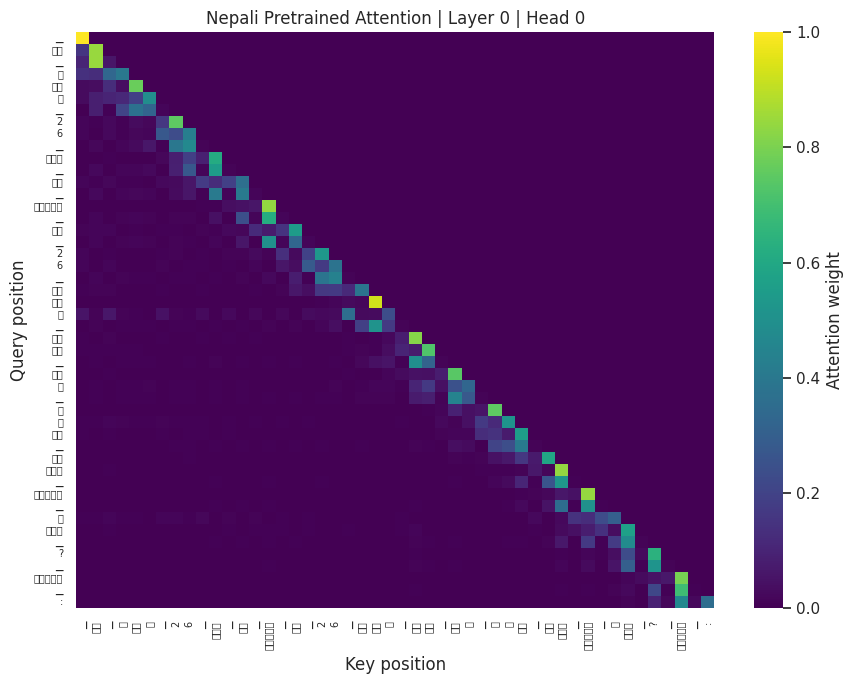

/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2319 (\N{DEVANAGARI LETTER E}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/li

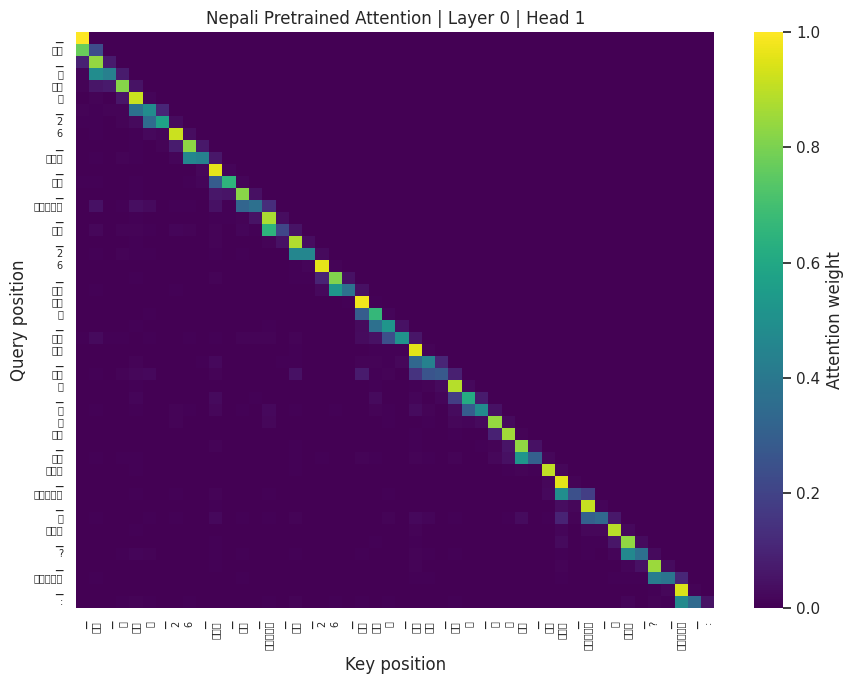

/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2319 (\N{DEVANAGARI LETTER E}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/li

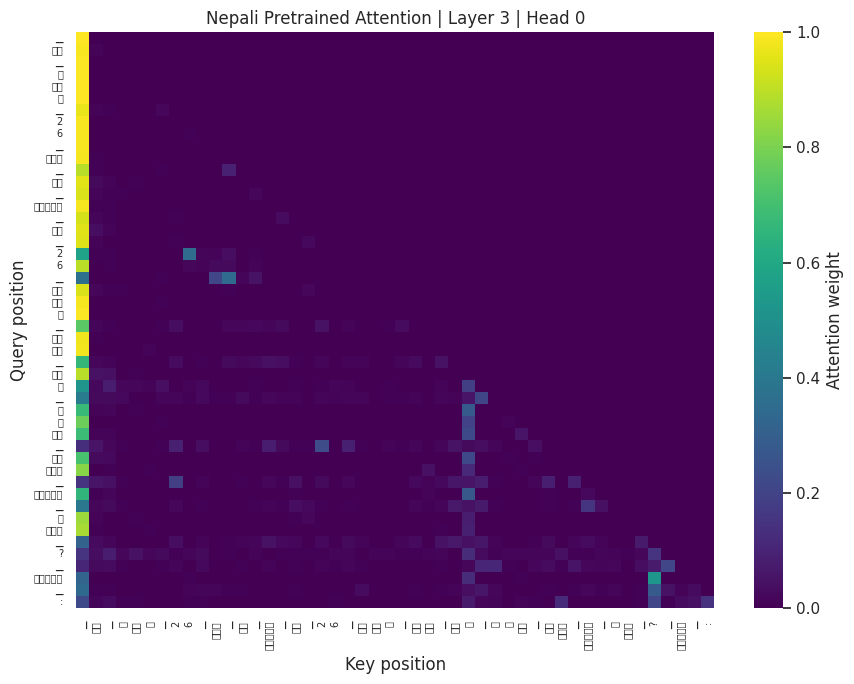

/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2319 (\N{DEVANAGARI LETTER E}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/li

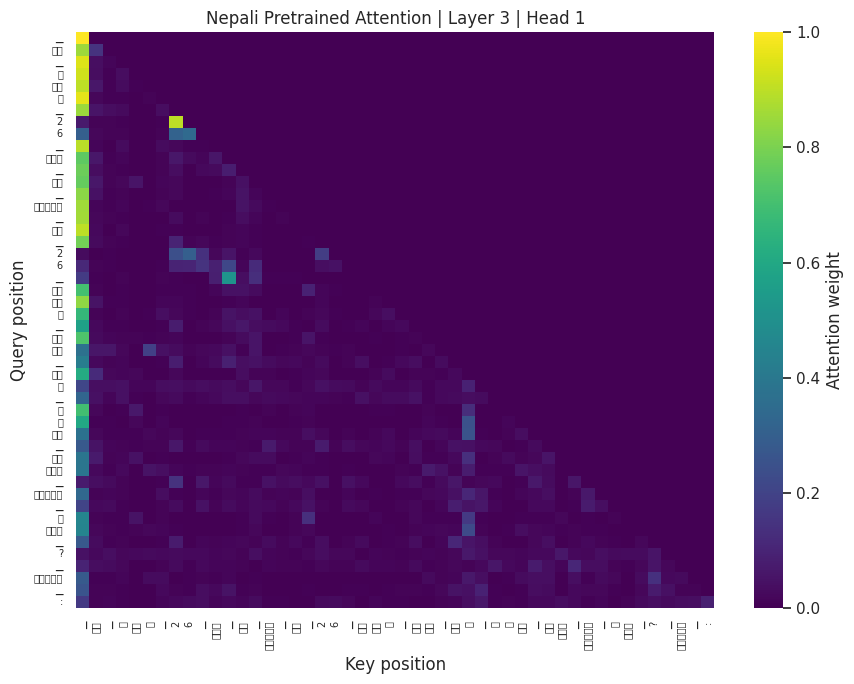

/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2319 (\N{DEVANAGARI LETTER E}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/li

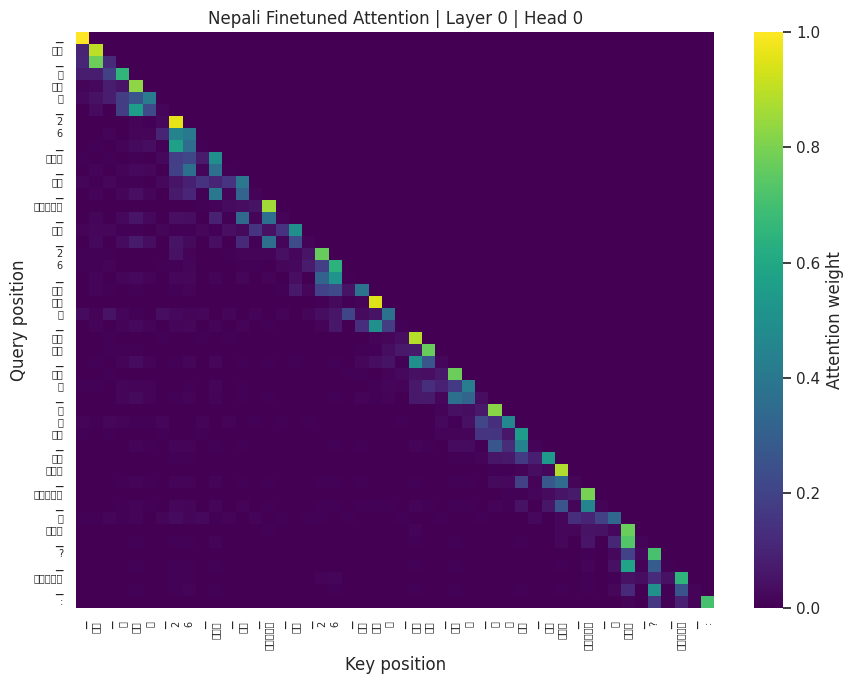

/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2319 (\N{DEVANAGARI LETTER E}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/li

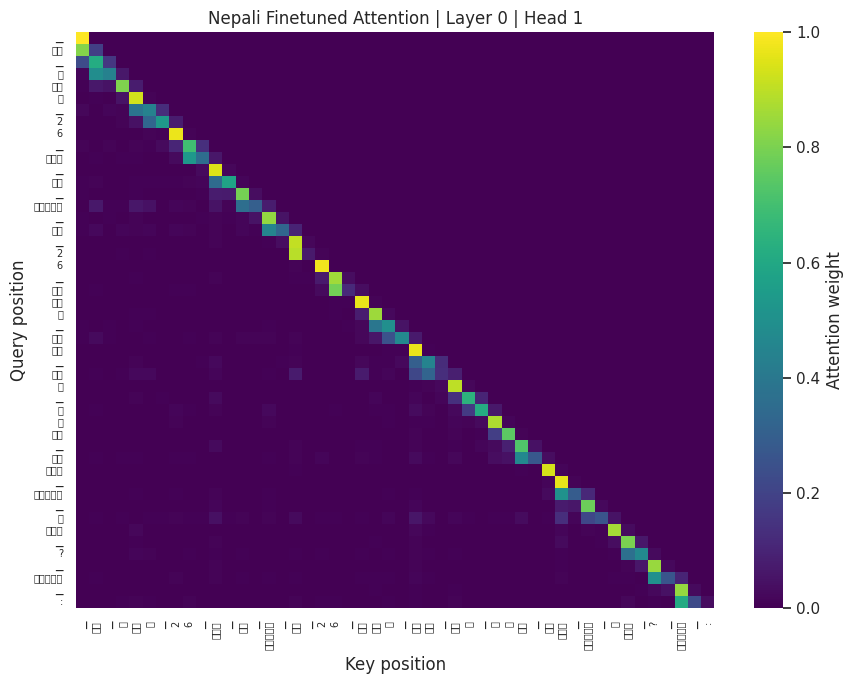

/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2319 (\N{DEVANAGARI LETTER E}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/li

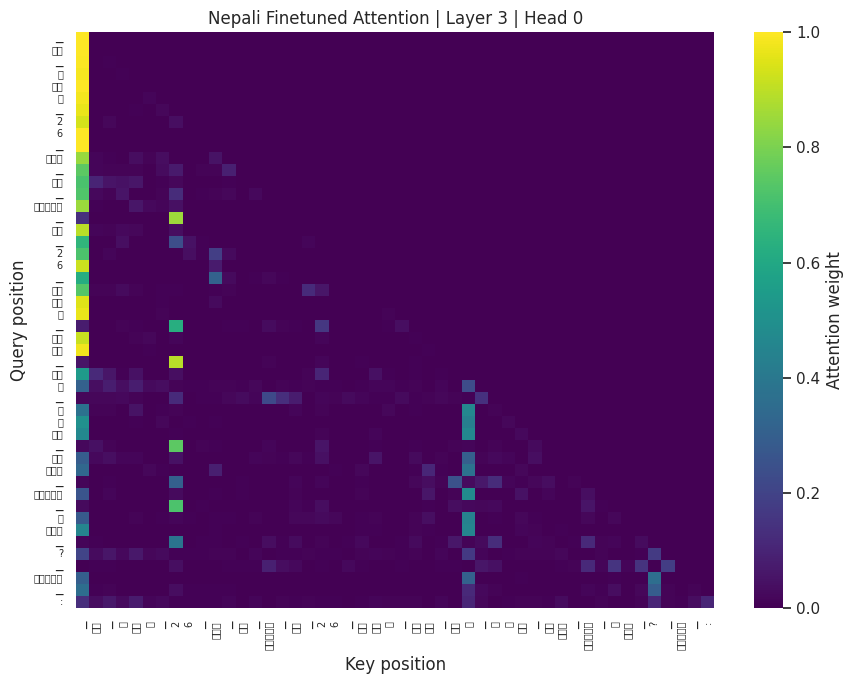

/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2319 (\N{DEVANAGARI LETTER E}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2325 (\N{DEVANAGARI LETTER KA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2358 (\N{DEVANAGARI LETTER SHA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2368 (\N{DEVANAGARI VOWEL SIGN II}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/li

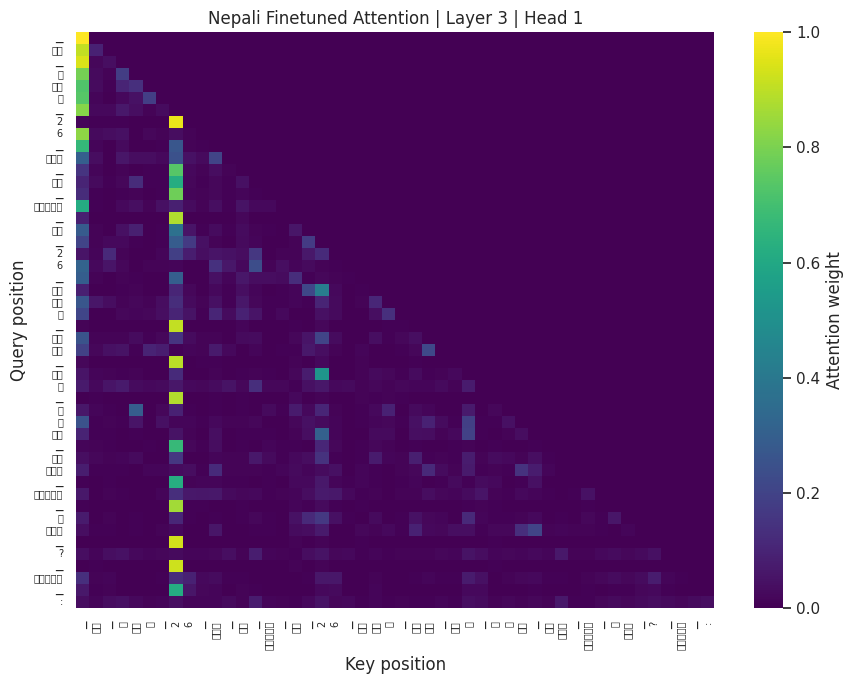

In [36]:







EARLY_LAYER = 0
LATE_LAYER = N_LAYERS - 1
HEATMAP_HEADS = list(range(min(2, N_HEADS)))

def plot_attention_heatmap(model_obj, row, layer_idx, head_idx, state_name):
    ids, maps = get_attention_for_row(model_obj, row)
    attn = maps[layer_idx][0, head_idx].detach().float().cpu().numpy()

    labels = token_labels(ids)

    labels = [str(x)[:16] for x in labels]

    plt.figure(figsize=(9, 7))
    sns.heatmap(
        attn,
        cmap="viridis",
        xticklabels=labels,
        yticklabels=labels,
        cbar_kws={"label": "Attention weight"},
    )
    plt.xlabel("Key position")
    plt.ylabel("Query position")
    plt.title(
        f"{INFO['name']} {state_name} Attention | "
        f"Layer {layer_idx} | Head {head_idx}"
    )
    plt.xticks(rotation=90, fontsize=7)
    plt.yticks(rotation=0, fontsize=7)
    plt.tight_layout()

    filename = (
        f"attention_heatmap_{state_name.lower()}_"
        f"layer_{layer_idx}_head_{head_idx}.png"
    )
    plt.savefig(PLOT_OUT / filename, dpi=200, bbox_inches="tight")
    plt.show()

for state_name, model_obj in [
    ("Pretrained", pretrained_model),
    ("Finetuned", finetuned_model),
]:
    for layer_idx in [EARLY_LAYER, LATE_LAYER]:
        for head_idx in HEATMAP_HEADS:
            plot_attention_heatmap(
                model_obj,
                attention_row,
                layer_idx,
                head_idx,
                state_name,
            )

## 14.8 Attention interpretation table

In [37]:




attention_interpretation_rows = []
for layer in range(N_LAYERS):
    for head in range(N_HEADS):
        ft_distance = ft_d[layer, head]
        relative_distance = ft_distance / max(1, CONTEXT_LEN - 1)

        if relative_distance < 0.15:
            locality = "local"
        elif relative_distance > 0.35:
            locality = "long-range"
        else:
            locality = "intermediate"

        attention_interpretation_rows.append({
            "layer": layer,
            "head": head,
            "finetuned_entropy": float(ft_e[layer, head]),
            "finetuned_mean_distance": float(ft_distance),
            "relative_distance_to_context": float(relative_distance),
            "descriptive_locality": locality,
            "entropy_change": float(ft_e[layer, head] - pre_e[layer, head]),
            "distance_change": float(ft_d[layer, head] - pre_d[layer, head]),
        })

attention_interpretation_df = pd.DataFrame(attention_interpretation_rows)
save_display_table(
    attention_interpretation_df,
    "attention_head_interpretation",
)

,layer,head,finetuned_entropy,finetuned_mean_distance,relative_distance_to_context,descriptive_locality,entropy_change,distance_change
0,0,0,1.314674,2.810021,0.011020,local,0.000773,0.383716
1,0,1,1.026656,2.567717,0.010069,local,0.063759,0.293177
2,0,2,0.683404,1.432235,0.005617,local,0.028698,0.183515
3,0,3,2.038074,7.155775,0.028062,local,-0.053248,0.145041
4,1,0,2.249186,9.841940,0.038596,local,-0.070935,1.540318
5,1,1,2.351499,7.257407,0.028460,local,0.074397,1.493621
6,1,2,2.251760,13.210347,0.051805,local,-0.299842,0.536957
7,1,3,2.541169,11.335147,0.044452,local,-0.019518,-0.192836
8,2,0,1.579972,15.124960,0.059314,local,0.120005,-0.692129
9,2,1,2.180379,6.552267,0.025695,local,0.226574,2.215612


,layer,head,finetuned_entropy,finetuned_mean_distance,relative_distance_to_context,descriptive_locality,entropy_change,distance_change
0,0,0,1.314674,2.810021,0.011020,local,0.000773,0.383716
1,0,1,1.026656,2.567717,0.010069,local,0.063759,0.293177
2,0,2,0.683404,1.432235,0.005617,local,0.028698,0.183515
3,0,3,2.038074,7.155775,0.028062,local,-0.053248,0.145041
4,1,0,2.249186,9.841940,0.038596,local,-0.070935,1.540318
5,1,1,2.351499,7.257407,0.028460,local,0.074397,1.493621
6,1,2,2.251760,13.210347,0.051805,local,-0.299842,0.536957
7,1,3,2.541169,11.335147,0.044452,local,-0.019518,-0.192836
8,2,0,1.579972,15.124960,0.059314,local,0.120005,-0.692129
9,2,1,2.180379,6.552267,0.025695,local,0.226574,2.215612


## 14.9 Phase 3 artifact manifest and Hugging Face status

In [38]:


artifact_rows = []
for path in sorted(OUT.rglob("*")):
    if path.is_file():
        artifact_rows.append({
            "relative_path": str(path.relative_to(OUT)),
            "size_kb": round(path.stat().st_size / 1024, 2),
            "type": path.suffix.lower() or "file",
        })

artifact_manifest_df = pd.DataFrame(artifact_rows)
save_display_table(artifact_manifest_df, "phase3_artifact_manifest")



if HF_PUSH_ENABLED:
    for local_path in [
        OUT / "finetune_config.json",
        METRIC_OUT / "reasoning_results.json",
        METRIC_OUT / "attention_summary.json",
    ]:
        if local_path.exists():
            hf_api.upload_file(
                path_or_fileobj=str(local_path),
                path_in_repo=f"phase3/{local_path.name}",
                repo_id=HF_REPO_ID,
                repo_type="model",
                commit_message=f"Upload Phase 3 artifact {local_path.name}",
            )

    print(f"HF repository: {HF_REPO_ID}")
    print("Checkpoint files:", len(list(CKPT_OUT.glob("*.pt"))))
else:
    print("HF upload skipped because HF_TOKEN is not set.")

print("\nPhase 3 reporting complete.")
print(f"Tables: {TABLE_OUT}")
print(f"Plots:  {PLOT_OUT}")
print(f"Checkpoints: {CKPT_OUT}")

,relative_path,size_kb,type
0,checkpoints/final.pt,285814.66,.pt
1,checkpoints/last.pt,285814.38,.pt
2,checkpoints/step_000100.pt,285828.87,.pt
3,checkpoints/step_000200.pt,285828.94,.pt
4,checkpoints/step_000300.pt,285828.94,.pt
...,...,...,...
65,plots/pretrained_early_L0_H3.png,55.22,.png
66,src/__pycache__/model.cpython-312.pyc,11.14,.pyc
67,src/__pycache__/tokenizers.cpython-312.pyc,15.67,.pyc
68,src/model.py,6.25,.py


HF upload skipped because HF_TOKEN is not set.

Phase 3 reporting complete.
Tables: /kaggle/working/phase3_ne/metrics/tables
Plots:  /kaggle/working/phase3_ne/plots
Checkpoints: /kaggle/working/phase3_ne/checkpoints
